# NeuroMotion — EEGNet Motor-Imagery Training & Evaluation Notebook

Classifies EEG into **Rest / Left-hand imagery / Right-hand imagery** (PhysioNet EEGMMIDB, runs R04/R08/R12) with a Braindecode `EEGNet`, and exports a model that
the Streamlit app (`app.py`) can load. 

## Two training protocols (both are in this notebook)

| | **A. Regular training — subject-independent** (Steps 8–14) | **B. All-subject training — personalised** (Step 15) |
|---|---|---|
| Question answered | How well does the model work on a **person it has never seen**? | How well does a model that has seen **all subjects** work on **held-out runs** of the best subjects? |
| Test set | Whole subjects (5-fold grouped cross-validation, then 6 held-out demo subjects) | A few runs (default `R12`) of the best-decoding subjects |
| Training set | Other subjects | All other data, including the *other runs* of the test subjects |
| Typical result | Honest, lower | Optimistic, higher (see caveats in Step 15) |
| Exported to | `../artifacts/all_subject_deployment/` | `../artifacts/all_subjects_best_runs_holdout/` |

## Notebook map

| Step | What happens |
|---|---|
| 0 | Imports, folders, one CONFIG block |
| 1–2 | Read EDF files exactly like the app; load all subjects; auto-exclude anomalous recordings |
| 3 | Normalization |
| 4–5 | Training recipe; augmentation, training loop, calibration, confidence gate |
| 6 | **Evaluation toolkit** (metrics + graphs, used for every result below) |
| 7–9 | Protocol A: cross-validation engine, run it, full evaluation report with graphs |
| 10 | Optional ablations |
| 11–13 | Protocol A: train the deployment model, export for the app, contract test |
| 14 | Protocol A: deployment model report on the demo subjects |
| 15 | Protocol B: all-subject model, report, export, contract test |
| 16 | Final summary and how to run the app |

## Metrics glossary (used in all reports)

For each class, with TP/FP/FN = true positives / false positives / false negatives:

* **Precision** = TP / (TP + FP): of the windows the model *called* "Left", how many really were Left. Low precision for Left/Right means the virtual object would often move when it should not.
* **Recall** (sensitivity) = TP / (TP + FN): of the windows that really were Left, how many the model found. Low recall means missed commands.
* **F1** = harmonic mean of precision and recall — one number that is low if *either* is low.
* **Accuracy** = correct / all. Misleading here because *Rest* is ~50 % of all windows (always saying "Rest" already scores ≈ 0.50 — the **majority baseline**).
* **Balanced accuracy** = mean of the three recalls (chance = 0.333). **Macro-averages** weight the three classes equally; **weighted** averages weight by class size.
* **Cohen's κ / MCC**: agreement beyond chance (0 = chance, 1 = perfect); robust to class imbalance.
* **ROC-AUC (one-vs-rest)**: probability a random window of a class gets a higher score than a window of another class (0.5 = chance). **Average precision (AP)** summarises the precision–recall curve.
* **Log-loss** and **ECE** (expected calibration error): how trustworthy the *confidence numbers* are. The app's confidence gate relies on them.

## Step 0 — Imports, folders and the single CONFIG block

* **`NM_QUICK=1`** (environment variable) shrinks everything (few epochs/folds) – only for smoke-testing the code.
* **`NM_DATA`, `NM_OUT`, `NM_ART`** override the data/output/artifact folders without editing the notebook.

In [18]:
import os, sys, json, time, copy, math, re, shutil, warnings, random
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import mne
from braindecode.models import EEGNet
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, roc_curve, auc, precision_recall_curve, average_precision_score, cohen_kappa_score, matthews_corrcoef, log_loss, roc_auc_score


mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")

# ------------------------------- CONFIG (edit here) -------------------------------
QUICK_RUN = os.environ.get("NM_QUICK", "0") == "1"       # True only for code smoke tests
SEED = 42
DATA_ROOT    = Path(os.environ.get("NM_DATA", "data"))                 # contains S001/S001R04.edf ...
OUTPUT_ROOT  = Path(os.environ.get("NM_OUT",  "outputs"))
ARTIFACT_DIR = Path(os.environ.get("NM_ART",  "artifacts")) / "all_subject_deployment"
N_SUBJECTS_LIMIT = int(os.environ.get("NM_N_SUBJECTS", "109"))            # 109 = all PhysioNet subjects
SUBJECT_IDS = [f"S{i:03d}" for i in range(1, N_SUBJECTS_LIMIT + 1)]
RUNS = ["R04", "R08", "R12"]            # imagined left/right fist runs (T0 rest, T1 left, T2 right)

# Preprocessing – these exact values are written to the model config and re-used by app.py
SAMPLING_RATE = 160.0
N_CHANNELS    = 64
BANDPASS      = (4.0, 38.0)             # Hz
EPOCH_WINDOW  = (0.5, 3.5)              # seconds after the cue
CLASS_NAMES   = ["Rest", "Left Hand", "Right Hand"]
ANNOTATION_TO_LABEL = {"T0": 0, "T1": 1, "T2": 2}

NORMALIZATION_MODE = "per_recording"    # "per_recording" (best, needs app patch)  |  "global" (unmodified app)

# Evaluation protocol
N_FOLDS         = 3 if QUICK_RUN else 5
VAL_FRACTION    = 0.15                  # share of *training subjects* held back for epoch selection / calibration
N_DEMO_SUBJECTS = 2 if QUICK_RUN else 6 # subjects never touched in training: use them in the app demo
GATE_PENALTY    = 2.0                   # wrong movement command costs this many correct ones when choosing the threshold
USE_CACHE       = True                  # cache the preprocessed epochs (saves ~10 min on re-runs)

RUN_ABLATIONS       = True             # optional: ~6 extra CV runs, shows which ingredient matters most

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| quick run:", QUICK_RUN, "| subjects requested:", len(SUBJECT_IDS))
print("data root:", DATA_ROOT.resolve())

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

device: cuda | quick run: False | subjects requested: 109
data root: C:\Users\cdsch\OneDrive\Documents\AIS\NeuroMotion\data


## Step 1 — Read one recording exactly the way the app reads it

Steps inside the function:
1. Read the EDF with MNE and check the sampling rate is 160 Hz.
2. Keep EEG channels only and check there are exactly 64 (reference channel order comes from the first good file).
3. Band-pass 4–38 Hz on the continuous signal (covers mu 8–13 Hz and beta 13–30 Hz, where motor-imagery changes live).
4. Find the `T0/T1/T2` annotations → events (`T0` rest, `T1` imagined left fist, `T2` imagined right fist).
5. Cut 0.5 s – 3.5 s after each cue (skips the reaction transient, keeps 3 s = 481 samples), rejecting epochs that overlap bad-segment annotations.
6. Convert volts → microvolts (float32).

In [2]:
def build_edf_index(root):
    """Map 'S001R04.edf' -> path. First match in sorted order wins (same rule as app.locate_edf)."""
    root = Path(root)
    if not root.exists():
        raise FileNotFoundError(f"Dataset folder does not exist: {root.resolve()}")
    index = {}
    for p in sorted(root.rglob("S[0-9][0-9][0-9]R[0-9][0-9].edf")):
        index.setdefault(p.name, p)
    return index

def load_run(edf_path, expected_channels=None):
    raw = mne.io.read_raw_edf(edf_path, preload=True, verbose="ERROR")
    sfreq = float(raw.info["sfreq"])
    if not np.isclose(sfreq, SAMPLING_RATE):
        raise ValueError(f"sampling rate {sfreq:g} Hz (expected {SAMPLING_RATE:g})")
    raw.pick(picks="eeg")
    if expected_channels is None:
        if len(raw.ch_names) != N_CHANNELS:
            raise ValueError(f"{len(raw.ch_names)} EEG channels (expected {N_CHANNELS})")
    else:
        if sorted(raw.ch_names) != sorted(expected_channels):
            raise ValueError("EEG channel set differs from the reference recording")
        raw.pick(picks=list(expected_channels))                 # enforce the same channel order
    raw.filter(l_freq=BANDPASS[0], h_freq=BANDPASS[1], picks="eeg", verbose="ERROR")

    events, found = mne.events_from_annotations(raw, regexp=r"^(T0|T1|T2)$", verbose="ERROR")
    missing = sorted(set(ANNOTATION_TO_LABEL) - set(found))
    if missing:
        raise ValueError(f"missing annotations {missing}")
    event_id = {name: found[name] for name in ANNOTATION_TO_LABEL}
    epochs = mne.Epochs(raw, events, event_id=event_id, tmin=EPOCH_WINDOW[0], tmax=EPOCH_WINDOW[1],
                        baseline=None, picks="eeg", preload=True, reject_by_annotation=True, verbose="ERROR")
    X = epochs.get_data().astype(np.float32) * 1e6                # microvolts
    if len(X) == 0 or not np.isfinite(X).all():
        raise ValueError("no valid / non-finite epochs")
    code_to_label = {event_id[n]: ANNOTATION_TO_LABEL[n] for n in ANNOTATION_TO_LABEL}
    y = np.array([code_to_label[int(c)] for c in epochs.events[:, 2]], dtype=np.int64)
    return {"X": X, "y": y, "ch_names": list(raw.ch_names)}

print("loader ready")

loader ready


## Step 2 — Load every subject and automatically exclude anomalous recordings

PhysioNet EEGMMIDB has a handful of recordings that differ from the rest (other sampling rate, missing annotations, odd channel sets).
A subject is **kept only if all three runs (R04, R08, R12) load cleanly, have 160 Hz / 64 channels and contain all three classes**.
Excluded subjects and the reason are printed so nothing disappears silently.

The result is stored in flat arrays:

* `X` – epochs, shape `(n_epochs, 64, 481)` in µV
* `y` – labels `0/1/2`
* `subj` – subject ID of every epoch (used to *group* the cross-validation so one person is never in both train and test)
* `rec` – recording ID such as `S001R04` (used for per-recording normalization)

In [3]:
def load_all(subject_ids):
    sig = json.dumps({"subs": subject_ids, "bp": BANDPASS, "win": EPOCH_WINDOW, "runs": RUNS, "v": 1})
    cache = OUTPUT_ROOT / "cache" / "epochs_cache.npz"
    if USE_CACHE and cache.exists():
        z = np.load(cache, allow_pickle=True)
        if str(z["sig"]) == sig:
            print("loaded epochs from cache:", cache)
            return (z["X"], z["y"], z["subj"], z["rec"], list(z["ch_names"]),
                    pd.DataFrame(z["excluded"].tolist(), columns=["subject", "reason"]))
    index = build_edf_index(DATA_ROOT)
    reference, Xs, ys, subs, recs, excluded = None, [], [], [], [], []
    t0 = time.time()
    for k, sid in enumerate(subject_ids, 1):
        loaded, reason = [], None
        for run in RUNS:
            path = index.get(f"{sid}{run}.edf")
            if path is None:
                reason = f"{sid}{run}.edf not found"; break
            try:
                d = load_run(path, reference)
                if len(np.unique(d["y"])) < 3 or len(d["y"]) < 15:
                    raise ValueError("fewer than 3 classes or < 15 epochs")
            except Exception as e:
                reason = f"{sid}{run}: {e}"; break
            if reference is None:
                reference = d["ch_names"]
            loaded.append((run, d))
        if reason is not None:
            excluded.append((sid, reason)); continue
        for run, d in loaded:
            Xs.append(d["X"]); ys.append(d["y"])
            subs += [sid] * len(d["y"]); recs += [f"{sid}{run}"] * len(d["y"])
        if k % 10 == 0:
            print(f"  {k}/{len(subject_ids)} subjects processed ({time.time()-t0:.0f}s)")
    if not Xs:
        raise RuntimeError("No usable recordings found. Check DATA_ROOT (expects S001/S001R04.edf ...).")
    X = np.concatenate(Xs).astype(np.float32); y = np.concatenate(ys)
    subj, rec = np.array(subs), np.array(recs)
    if USE_CACHE:
        cache.parent.mkdir(parents=True, exist_ok=True)
        np.savez(cache, X=X, y=y, subj=subj, rec=rec, ch_names=np.array(reference), sig=sig,
                 excluded=np.array(excluded, dtype=object).reshape(-1, 2))
    return X, y, subj, rec, reference, pd.DataFrame(excluded, columns=["subject", "reason"])

X, y, subj, rec, CH_NAMES, excluded_df = load_all(SUBJECT_IDS)
N_TIMES = X.shape[2]
SUBJECTS = sorted(np.unique(subj))
print(f"\neligible subjects: {len(SUBJECTS)} | excluded: {len(excluded_df)} | epochs: {len(y)} | shape per epoch: {X.shape[1:]}")
print("class counts (Rest/Left/Right):", np.bincount(y, minlength=3).tolist())
if len(excluded_df):
    display(excluded_df)
assert X.shape[1] == N_CHANNELS and len(CH_NAMES) == N_CHANNELS

loaded epochs from cache: outputs\cache\epochs_cache.npz

eligible subjects: 106 | excluded: 3 | epochs: 9535 | shape per epoch: (64, 481)
class counts (Rest/Left/Right): [4768, 2405, 2362]


,subject,reason
0,S088,S088R04: sampling rate 128 Hz (expected 160)
1,S092,S092R04: sampling rate 128 Hz (expected 160)
2,S100,S100R04: sampling rate 128 Hz (expected 160)


## Step 3 — Normalization (the biggest single accuracy lever)

Raw EEG amplitude differs by factors of 2–5 between people (skull thickness, electrode contact, impedance) and even between sessions of the same person.
A network trained with *one* global mean/std sees "loud" and "quiet" people as different signals.

* **`per_recording` (default):** for each recording (e.g. `S007R08`) every channel is z-scored with that recording's own mean and standard deviation
  (computed over all its epochs and time points). This needs no label information, so it uses nothing the app does not also have — the app computes the same statistics from
  the recording it replays.
* **`global`:** one mean/std per channel computed from the *training* subjects only.

The helper below creates the per-recording version **once** (labels are never used, so there is no leakage).
For `global` mode the statistics are re-computed inside every cross-validation fold from that fold's training subjects only.

In [4]:
def zscore_per_recording(X, rec):
    """Per-recording, per-channel z-score; identical arithmetic to the patched app.load_recording."""
    Xn = np.empty_like(X)
    for r in np.unique(rec):
        m = rec == r
        a = X[m]
        mean = a.mean(axis=(0, 2), keepdims=True).astype(np.float32)
        std = a.std(axis=(0, 2), keepdims=True).astype(np.float32)
        std = np.where(std < 1e-6, 1.0, std)
        Xn[m] = ((a - mean) / std).astype(np.float32)
    return Xn

def global_stats(X, idx):
    mean = np.mean(X[idx], axis=(0, 2), dtype=np.float64).astype(np.float32)
    std = np.std(X[idx], axis=(0, 2), dtype=np.float64).astype(np.float32)
    return mean, np.where(std < 1e-6, 1.0, std).astype(np.float32)

X_REC = None
def prepare_inputs(norm, train_idx):
    """Return the normalised array used for this recipe/fold plus the global stats (None for per-recording)."""
    global X_REC
    if norm == "per_recording":
        if X_REC is None:
            X_REC = zscore_per_recording(X, rec)
        return X_REC, None
    mean, std = global_stats(X, train_idx)
    return ((X - mean[None, :, None]) / std[None, :, None]).astype(np.float32), (mean, std)

# quick sanity check on the first recording
_r = np.unique(rec)[0]; _m = rec == _r
_chk = zscore_per_recording(X[_m], rec[_m])
print(f"{_r}: raw std per channel (uV) min/max = {X[_m].std(axis=(0,2)).min():.1f}/{X[_m].std(axis=(0,2)).max():.1f}"
      f" -> after z-score mean|std = {_chk.mean():.3f}|{_chk.std():.3f}")

S001R04: raw std per channel (uV) min/max = 12.4/34.1 -> after z-score mean|std = 0.000|1.000


## Step 4 — The training recipe

A **recipe** is a dictionary of training choices. The model itself is fixed: `EEGNet(n_chans=64, n_outputs=3, n_times=481, sfreq=160)` with Braindecode defaults, because `app.py`
rebuilds exactly that constructor and loads the weights with `strict=True`. What we *can* choose is how it is trained:

| Choice | Value | Why |
|---|---|---|
| Normalization | per-recording z-score (`NORMALIZATION_MODE`) | removes amplitude differences between people/sessions |
| Epochs / selection | up to 60, **best epoch on validation subjects**, early stopping (patience 15) | EEGNet is small and noisy; stop when the validation score stops improving |
| Optimizer / schedule | AdamW (weight decay 1e-2), lr 2e-3, 3-epoch warm-up, cosine decay | stable start, smooth finish, mild regularisation |
| Loss | class-balanced cross-entropy + label smoothing 0.1 | *Rest* is ~50 % of data; balanced weights stop the model from just saying "Rest"; smoothing curbs over-confidence |
| Augmentation | time shift ±16 samples (±0.1 s), Gaussian noise, 5 % channel dropout (optional hemisphere flip) | cue timing and electrode quality vary between people |
| Confidence | temperature scaling fitted on validation data, baked into the last layer | the app uses `softmax(model(x))` as confidence; we make that number meaningful |

In [5]:
RECIPE = dict(name="main", norm=NORMALIZATION_MODE, epochs=60, batch=64, lr=2e-3, wd=1e-2, optimizer="adamw",
              balanced=True, smoothing=0.1, warmup=3, cosine=True,
              aug=dict(shift=16, noise=0.05, chdrop=0.05, flip=False),
              patience=15, select="best_val", temperature=True)

if QUICK_RUN:                                   # smoke-test only
    RECIPE["epochs"] = 3; RECIPE["warmup"] = 1; RECIPE["patience"] = 2
print("training recipe:", json.dumps(RECIPE, indent=1))

training recipe: {
 "name": "main",
 "norm": "per_recording",
 "epochs": 60,
 "batch": 64,
 "lr": 0.002,
 "wd": 0.01,
 "optimizer": "adamw",
 "balanced": true,
 "smoothing": 0.1,
 "warmup": 3,
 "cosine": true,
 "aug": {
  "shift": 16,
  "noise": 0.05,
  "chdrop": 0.05,
  "flip": false
 },
 "patience": 15,
 "select": "best_val",
 "temperature": true
}


## Step 5 — Building blocks: augmentation, training loop, calibration, confidence gate

**5a. Augmentation** (training only). Each is small enough not to destroy the mu/beta rhythm but forces robustness:
*time shift* (the exact cue timing varies between people), *Gaussian noise* (electrode noise), *channel dropout* (a bad electrode),
and an optional *hemisphere flip* (mirror left↔right channels **and swap Left/Right labels** – physiologically plausible but off by default; try it in the ablations).

**5b. Training loop.** Mini-batches → augmentation → loss → AdamW step. After each epoch the model is scored on the validation subjects
(balanced accuracy, tie-broken by loss) and the best weights are restored at the end. Test subjects are never touched here.

**5c. Temperature scaling.** A network's softmax confidence is usually miscalibrated. We fit one number `T` on validation logits (minimizing log-loss) so that
`softmax(logits / T)` is better calibrated. Because the app just does `softmax(model(x))`, we **bake `T` into the last layer** (divide its weights and bias by `T`) — the exported weights then give calibrated probabilities with no app change.

**5d. Confidence gate.** The app only moves the object if confidence ≥ threshold *and* the class is Left/Right. `gate_stats` measures what that policy would do;
`select_threshold` picks the threshold on **validation data only**, maximizing `correct commands − GATE_PENALTY × wrong commands` (a wrong movement is worse than a missed one).

In [6]:
# ---------- hemisphere mirror permutation (only used if aug['flip'] is on) ----------
def mirror_permutation(names):
    def partner(n):
        m = re.match(r"^([A-Za-z]+?)(\d+)?\.*$", n)
        base, num = m.group(1), m.group(2)
        if num is None: return n
        k = int(num); k2 = k + 1 if k % 2 else k - 1
        return f"{base}{k2}"
    stripped = [n.rstrip(".") for n in names]
    pos = {n: i for i, n in enumerate(stripped)}
    return np.array([pos.get(partner(n), i) for i, n in enumerate(stripped)])
MIRROR = mirror_permutation(CH_NAMES)

def augment(xb, yb, aug, flip_perm):
    B, C, T = xb.shape
    if aug["flip"] and flip_perm is not None:
        sel = torch.rand(B, device=xb.device) < 0.5
        if sel.any():
            perm = torch.as_tensor(flip_perm, device=xb.device)
            xb = xb.clone(); yb = yb.clone()
            xb[sel] = xb[sel][:, perm]
            l, r = yb[sel] == 1, yb[sel] == 2
            ys = yb[sel]; ys[l] = 2; ys[r] = 1; yb[sel] = ys
    if aug["shift"] > 0:
        sh = torch.randint(-aug["shift"], aug["shift"] + 1, (B,))
        xb = torch.stack([torch.roll(xb[i], int(sh[i]), dims=-1) for i in range(B)])
    if aug["noise"] > 0:
        xb = xb + aug["noise"] * torch.randn_like(xb)
    if aug["chdrop"] > 0:
        xb = xb * (torch.rand(B, C, 1, device=xb.device) > aug["chdrop"]).float()
    return xb, yb

@torch.no_grad()
def predict_logits(model, Xn, bs=256):
    model.eval()
    out = []
    for s in range(0, len(Xn), bs):
        xb = torch.from_numpy(np.ascontiguousarray(Xn[s:s + bs])).to(DEVICE)
        out.append(model(xb).reshape(len(xb), -1).float().cpu().numpy())
    return np.concatenate(out)

def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def lr_at(ep, r):
    lr = r["lr"]
    if r["cosine"]:
        lr = r["lr"] * (0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * ep / max(r["epochs"] - 1, 1))))
    if r["warmup"] > 0 and ep < r["warmup"]:
        lr *= (ep + 1) / r["warmup"]
    return lr

def train_model(Xtr, ytr, Xva, yva, r, seed, verbose=False):
    set_seed(seed)
    n, C, T = Xtr.shape
    model = EEGNet(n_chans=C, n_outputs=3, n_times=T, sfreq=SAMPLING_RATE).to(DEVICE)
    opt = (torch.optim.AdamW(model.parameters(), lr=r["lr"], weight_decay=r["wd"]) if r["optimizer"] == "adamw"
           else torch.optim.Adam(model.parameters(), lr=r["lr"]))
    weight = None
    if r["balanced"]:
        cnt = np.bincount(ytr, minlength=3).astype(np.float32)
        weight = torch.tensor(cnt.sum() / (3 * np.maximum(cnt, 1)), device=DEVICE)
    rng = np.random.default_rng(seed)
    best_state, best_score, best_ep, since, hist = None, -np.inf, -1, 0, []
    for ep in range(r["epochs"]):
        for g in opt.param_groups: g["lr"] = lr_at(ep, r)
        model.train(); order = rng.permutation(n); tl, nb = 0.0, 0
        for s in range(0, n, r["batch"]):
            bi = order[s:s + r["batch"]]
            if len(bi) < 2: continue                       # BatchNorm needs >1 sample
            xb = torch.from_numpy(Xtr[bi]).to(DEVICE); yb = torch.from_numpy(ytr[bi]).to(DEVICE)
            xb, yb = augment(xb, yb, r["aug"], MIRROR)
            loss = F.cross_entropy(model(xb), yb, weight=weight, label_smoothing=r["smoothing"])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tl += loss.item(); nb += 1
        row = {"epoch": ep + 1, "train_loss": tl / max(nb, 1), "lr": lr_at(ep, r)}
        if Xva is not None:
            lg = predict_logits(model, Xva)
            row["val_loss"] = float(F.cross_entropy(torch.from_numpy(lg), torch.from_numpy(yva)))
            row["val_bal_acc"] = float(balanced_accuracy_score(yva, lg.argmax(1)))
            score = row["val_bal_acc"] - 1e-3 * row["val_loss"]
            if score > best_score:
                best_score, best_ep, since = score, ep + 1, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                since += 1
        hist.append(row)
        if verbose: print(row)
        if r["patience"] and Xva is not None and since >= r["patience"]: break
    if r["select"] == "best_val" and best_state is not None:
        model.load_state_dict(best_state)
    else:
        best_ep = len(hist)
    model.eval()
    return model, {"best_epoch": best_ep, "history": pd.DataFrame(hist)}

def fit_temperature(logits, labels):
    z = torch.from_numpy(logits); t = torch.from_numpy(labels)
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100)
    def closure():
        opt.zero_grad(); loss = F.cross_entropy(z / log_t.exp(), t); loss.backward(); return loss
    opt.step(closure)
    return float(log_t.exp().clamp(0.25, 8.0))

def bake_temperature(model, T):
    """softmax(W h / T + b / T): divide the final conv layer by T -> exported weights are already calibrated."""
    with torch.no_grad():
        layer = model.final_layer.conv_classifier
        layer.weight.div_(T); layer.bias.div_(T)

def gate_stats(probs, y, thr):
    pred, conf = probs.argmax(1), probs.max(1)
    acc_m = conf >= thr; cmd = acc_m & (pred > 0)
    ok, bad = cmd & (pred == y), cmd & (pred != y)
    n_rest = max(int((y == 0).sum()), 1)
    return {"threshold": round(float(thr), 3),
            "accepted_rate": float(acc_m.mean()),
            "accepted_accuracy": float((pred[acc_m] == y[acc_m]).mean()) if acc_m.any() else float("nan"),
            "movement_command_rate": float(cmd.mean()),
            "correct_command_rate": float(ok.mean()),
            "wrong_command_rate": float(bad.mean()),
            "command_precision": float(ok.sum() / cmd.sum()) if cmd.any() else float("nan"),
            "false_movement_on_true_rest_rate": float((cmd & (y == 0)).sum() / n_rest)}

THRESHOLD_GRID = np.round(np.arange(0.50, 0.951, 0.05), 2)
def select_threshold(probs, y):
    best, best_u = 0.60, -np.inf
    for t in THRESHOLD_GRID:
        g = gate_stats(probs, y, t); u = g["correct_command_rate"] - GATE_PENALTY * g["wrong_command_rate"]
        if u > best_u: best, best_u = float(t), u
    return best
print("building blocks ready; mirror pairs found:", int((MIRROR != np.arange(len(MIRROR))).sum()), "of", len(MIRROR), "channels")

building blocks ready; mirror pairs found: 54 of 64 channels


## Step 6 — Evaluation toolkit: one function that produces every metric and graph

`show_report(y_true, probs, groups, title, tag)` is used for **every** result in this notebook (cross-validation, demo subjects, all-subject model), so all of them are
reported the same way. Given the true labels and the model's class probabilities it prints and saves:

**Tables** — overall metrics (accuracy, balanced accuracy, macro precision/recall/F1, weighted F1, κ, MCC, ROC-AUC, log-loss, ECE, majority baseline) and the per-class
precision / recall / F1 / support table (same layout as scikit-learn's `classification_report`).

**Figure 1 — "overview" (2 × 3):**
1. *Confusion matrix (counts)* – rows are the true class, columns the predicted class.
2. *Confusion matrix (row-normalised)* – the diagonal is each class's recall; off-diagonal shows what it is confused with (Left↔Right is the hard part).
3. *Precision / recall / F1 per class* – bars, with the majority baseline for reference.
4. *ROC curves (one-vs-rest)* with AUC per class — the diagonal is chance.
5. *Precision–recall curves* with average precision (AP) — dotted lines are each class's prevalence (chance level).
6. *Reliability diagram* – if the model says "80 % confident", is it right 80 % of the time? Bars on the diagonal = well calibrated.

**Figure 2 — "gate and subjects" (1 × 3):**
1. *Confidence histogram* for correct vs. wrong predictions – good models are confident when right and unsure when wrong.
2. *Confidence-gate trade-off* – for each threshold the app could use: share of windows accepted, share that become movement commands, the precision of those commands, wrong commands, and false movement on true Rest. The dashed line is the app's 0.60 default.
3. *Per-subject (or per-recording) accuracy* – EEG decoding varies enormously between people; the spread matters as much as the average.

Everything is also saved to `../outputs/figures/` (PNG) and `../outputs/reports/` (CSV).

In [7]:
FIG_DIR = OUTPUT_ROOT / "figures"; REPORT_DIR = OUTPUT_ROOT / "reports"
FIG_DIR.mkdir(parents=True, exist_ok=True); REPORT_DIR.mkdir(parents=True, exist_ok=True)
CLASS_COLORS = ["#7b6fb5", "#2a9d8f", "#e76f51"]            # Rest, Left, Right
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

def _prob(p):
    p = np.asarray(p, dtype=np.float64); return p / p.sum(1, keepdims=True)

def classification_table(y_true, probs):
    """precision / recall / F1 / support per class + macro, weighted and accuracy rows."""
    probs = _prob(probs); pred = probs.argmax(1)
    p, r, f, s = precision_recall_fscore_support(y_true, pred, labels=[0, 1, 2], zero_division=0)
    tab = pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=CLASS_NAMES)
    w = s / max(s.sum(), 1)
    tab.loc["macro avg"] = [p.mean(), r.mean(), f.mean(), s.sum()]
    tab.loc["weighted avg"] = [(p * w).sum(), (r * w).sum(), (f * w).sum(), s.sum()]
    tab.loc["accuracy"] = [np.nan, np.nan, accuracy_score(y_true, pred), s.sum()]
    return tab

def expected_calibration_error(probs, y_true, n_bins=10):
    conf, ok = probs.max(1), probs.argmax(1) == y_true
    edges = np.linspace(0, 1, n_bins + 1); ece, rows = 0.0, []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(ok[m].mean() - conf[m].mean()); rows.append((conf[m].mean(), ok[m].mean(), int(m.sum())))
    return float(ece), rows

def metrics_summary(y_true, probs):
    probs = _prob(probs); pred = probs.argmax(1)
    mp, mr, mf, _ = precision_recall_fscore_support(y_true, pred, labels=[0, 1, 2], average="macro", zero_division=0)
    try: auc_macro = float(roc_auc_score(y_true, probs, multi_class="ovr", average="macro", labels=[0, 1, 2]))
    except ValueError: auc_macro = float("nan")
    return {"n_windows": int(len(y_true)), "accuracy": accuracy_score(y_true, pred), "majority_baseline_accuracy": float(np.bincount(y_true, minlength=3).max() / len(y_true)),
            "balanced_accuracy": balanced_accuracy_score(y_true, pred), "macro_precision": mp, "macro_recall": mr, "macro_f1": mf,
            "weighted_f1": f1_score(y_true, pred, average="weighted", zero_division=0), "cohen_kappa": cohen_kappa_score(y_true, pred),
            "mcc": matthews_corrcoef(y_true, pred), "roc_auc_macro_ovr": auc_macro,
            "log_loss": float(log_loss(y_true, np.clip(probs, 1e-7, 1), labels=[0, 1, 2])), "ece": expected_calibration_error(probs, y_true)[0]}

def show_report(y_true, probs, groups, title, tag, thr=0.60):
    """Print tables, draw the two figures, save PNG/CSV. Returns (metrics dict, per-class table)."""
    y_true = np.asarray(y_true); probs = _prob(probs); pred = probs.argmax(1)
    m = metrics_summary(y_true, probs); tab = classification_table(y_true, probs)
    print(f"\n{'=' * 8} {title} {'=' * 8}")
    display(pd.DataFrame(m, index=["value"]).T.round(4)); display(tab.round(3))
    pd.DataFrame(m, index=["value"]).T.to_csv(REPORT_DIR / f"{tag}_metrics.csv"); tab.to_csv(REPORT_DIR / f"{tag}_classification_report.csv")

    # ---------------- figure 1 ----------------
    cm = confusion_matrix(y_true, pred, labels=[0, 1, 2]); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    Y = label_binarize_3(y_true)
    fig, ax = plt.subplots(2, 3, figsize=(17, 9.5)); fig.suptitle(f"{title} — overview", fontsize=14, y=1.0)
    for a, mat, fmt, name in ((ax[0, 0], cm, "d", "Confusion matrix (counts)"), (ax[0, 1], cmn, ".2f", "Confusion matrix (row-normalised = recall)")):
        a.imshow(mat, cmap="Blues", vmin=0, vmax=None if fmt == "d" else 1); a.grid(False)
        a.set_xticks(range(3)); a.set_yticks(range(3)); a.set_xticklabels(CLASS_NAMES, rotation=15); a.set_yticklabels(CLASS_NAMES)
        for i in range(3):
            for j in range(3):
                v = mat[i, j]; a.text(j, i, format(v, fmt), ha="center", va="center", color="white" if v > mat.max() * .6 else "black", fontsize=12)
        a.set_title(name); a.set_xlabel("predicted"); a.set_ylabel("true")
    a = ax[0, 2]; xs = np.arange(3); w = .26
    for k, (col, lab) in enumerate((("precision", "Precision"), ("recall", "Recall"), ("f1", "F1"))):
        bars = a.bar(xs + (k - 1) * w, tab.loc[CLASS_NAMES, col], w, label=lab)
        for b_ in bars: a.text(b_.get_x() + b_.get_width() / 2, b_.get_height() + .01, f"{b_.get_height():.2f}", ha="center", fontsize=8)
    a.axhline(m["majority_baseline_accuracy"], color="gray", ls=":", label="majority baseline"); a.set_xticks(xs); a.set_xticklabels(CLASS_NAMES)
    a.set_ylim(0, 1.08); a.set_title(f"Per-class precision / recall / F1  (macro F1 {m['macro_f1']:.3f})"); a.legend(fontsize=8)
    a = ax[1, 0]
    for c in range(3):
        if Y[:, c].sum() and (1 - Y[:, c]).sum():
            fpr, tpr, _ = roc_curve(Y[:, c], probs[:, c]); a.plot(fpr, tpr, color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} (AUC {auc(fpr, tpr):.2f})")
    a.plot([0, 1], [0, 1], "k:", lw=1); a.set_xlabel("false-positive rate"); a.set_ylabel("true-positive rate"); a.set_title("ROC curves (one-vs-rest)"); a.legend(fontsize=8)
    a = ax[1, 1]
    for c in range(3):
        if Y[:, c].sum():
            pr_, rc_, _ = precision_recall_curve(Y[:, c], probs[:, c]); a.plot(rc_, pr_, color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} (AP {average_precision_score(Y[:, c], probs[:, c]):.2f})")
            a.axhline(Y[:, c].mean(), color=CLASS_COLORS[c], ls=":", lw=.8)
    a.set_xlabel("recall"); a.set_ylabel("precision"); a.set_ylim(0, 1.02); a.set_title("Precision–recall curves (dotted = chance)"); a.legend(fontsize=8)
    a = ax[1, 2]; ece, rows = expected_calibration_error(probs, y_true)
    if rows:
        cf, ac, n = zip(*rows); a.bar(cf, ac, width=.07, alpha=.8, color="#4c78a8"); a.plot([0, 1], [0, 1], "k--", lw=1)
        for c_, a_, n_ in rows: a.text(c_, a_ + .01, str(n_), ha="center", fontsize=7)
    a.set_xlim(0, 1); a.set_ylim(0, 1.05); a.set_xlabel("mean confidence (max class probability)"); a.set_ylabel("accuracy in bin"); a.set_title(f"Reliability diagram (ECE {ece:.3f})")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{tag}_overview.png", dpi=130, bbox_inches="tight"); plt.show()

    # ---------------- figure 2 ----------------
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6)); fig.suptitle(f"{title} — confidence gate and groups", fontsize=13, y=1.03)
    conf, ok = probs.max(1), pred == y_true
    bins = np.linspace(1 / 3, 1, 21)
    ax[0].hist(conf[ok], bins=bins, alpha=.7, label=f"correct ({ok.sum()})", color="#2a9d8f"); ax[0].hist(conf[~ok], bins=bins, alpha=.7, label=f"wrong ({(~ok).sum()})", color="#e76f51")
    ax[0].axvline(thr, color="k", ls="--", lw=1); ax[0].set_xlabel("confidence (max probability)"); ax[0].set_ylabel("windows"); ax[0].set_title("Confidence: correct vs wrong"); ax[0].legend(fontsize=8)
    grid = np.linspace(0.34, 0.95, 32); gs = pd.DataFrame([gate_stats(probs, y_true, t) for t in grid])
    for col, lab in (("accepted_rate", "accepted (any class)"), ("movement_command_rate", "movement commands"), ("command_precision", "command precision"),
                     ("wrong_command_rate", "wrong commands"), ("false_movement_on_true_rest_rate", "false movement on true Rest")):
        ax[1].plot(gs["threshold"], gs[col], label=lab)
    ax[1].axvline(thr, color="k", ls="--", lw=1); ax[1].set_xlabel("confidence threshold"); ax[1].set_ylim(-.02, 1.02); ax[1].set_title("Confidence-gate trade-off"); ax[1].legend(fontsize=7)
    gs.to_csv(REPORT_DIR / f"{tag}_gate_tradeoff.csv", index=False)
    if groups is not None:
        groups = np.asarray(groups); names = sorted(np.unique(groups))
        accs = np.array([accuracy_score(y_true[groups == g], pred[groups == g]) for g in names]); order = np.argsort(accs)
        if len(names) <= 25:
            ax[2].bar(range(len(names)), accs[order], color="#4c78a8"); ax[2].set_xticks(range(len(names))); ax[2].set_xticklabels([names[i] for i in order], rotation=70, fontsize=8)
            ax[2].set_ylabel("accuracy")
        else:
            ax[2].hist(accs, bins=15, color="#4c78a8"); ax[2].set_xlabel("accuracy"); ax[2].set_ylabel("number of subjects")
        line = ax[2].axhline if len(names) <= 25 else ax[2].axvline        # bars: horizontal reference lines, histogram: vertical
        line(m["majority_baseline_accuracy"], color="gray", ls=":", label="majority baseline"); line(1 / 3, color="r", ls=":", label="chance (1/3)")
        ax[2].set_title(f"Accuracy per {'recording' if 'R' in str(names[0])[4:5] else 'subject'} (n={len(names)}, median {np.median(accs):.2f})"); ax[2].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{tag}_gate_and_groups.png", dpi=130, bbox_inches="tight"); plt.show()
    return m, tab

def label_binarize_3(y_true):
    return np.eye(3)[np.asarray(y_true)]

def plot_fold_metrics(folds, majority, title="Cross-validation folds"):
    fig, ax = plt.subplots(figsize=(8, 3.8)); x = np.arange(len(folds)); w = .26
    for k, (col, lab) in enumerate((("accuracy", "Accuracy"), ("balanced_accuracy", "Balanced accuracy"), ("macro_f1", "Macro-F1"))):
        ax.bar(x + (k - 1) * w, folds[col], w, label=f"{lab} (mean {folds[col].mean():.3f})")
    ax.axhline(majority, color="gray", ls=":", label=f"majority baseline {majority:.2f}"); ax.axhline(1 / 3, color="r", ls=":", lw=.8, label="chance 0.33")
    ax.set_xticks(x); ax.set_xticklabels([f"fold {f}" for f in folds["fold"]]); ax.set_ylim(0, 1); ax.set_title(title); ax.legend(fontsize=7, ncol=2)
    plt.tight_layout(); plt.savefig(FIG_DIR / "cv_fold_metrics.png", dpi=130); plt.show()
print("evaluation toolkit ready; figures -> ", FIG_DIR.resolve())

evaluation toolkit ready; figures ->  C:\Users\cdsch\OneDrive\Documents\AIS\NeuroMotion\outputs\figures


## Step 7 — Protocol A: subject-independent cross-validation (the fair test)

`StratifiedGroupKFold` splits **people**, not epochs: all epochs of one subject are in the same fold, and class proportions stay balanced.
For each of the 5 folds:

1. The fold's subjects are the **test set** (never used for any decision).
2. From the remaining subjects, ~15 % are held back as **validation subjects** (epoch selection, temperature, gate threshold) — training recipe only.
3. The model trains on the rest, then predicts the test subjects.

All out-of-fold (OOF) predictions are pooled, so every epoch of every subject is predicted exactly once by a model that never saw that subject.
We report accuracy, balanced accuracy, macro-F1, the **majority-class baseline** (predict "Rest" always – anything near that number is not learning),
per-subject results, and the **gate diagnostics** the app's Results page shows.

In [8]:
def run_cv(recipe, tag):
    print(f"\n=== CV: {tag} ({recipe['name']} recipe, norm={recipe['norm']}, {N_FOLDS} folds, device={DEVICE}) ===")
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    oof = np.zeros((len(y), 3), np.float32); oof_fold = np.full(len(y), -1)
    rows, val_thr, t_start = [], [], time.time()
    for fold, (tr, te) in enumerate(sgkf.split(np.zeros(len(y)), y, groups=subj), 1):
        Xn, _ = prepare_inputs(recipe["norm"], tr)
        need_val = recipe["select"] == "best_val" or recipe["temperature"]
        if need_val:
            a, b = next(GroupShuffleSplit(1, test_size=VAL_FRACTION, random_state=SEED + fold).split(tr, groups=subj[tr]))
            tr_fit, va = tr[a], tr[b]
        else:
            tr_fit, va = tr, None
        model, info = train_model(Xn[tr_fit], y[tr_fit], Xn[va] if need_val else None, y[va] if need_val else None, recipe, SEED + fold)
        lg_te = predict_logits(model, Xn[te]); T, thr = 1.0, 0.60
        if need_val:
            lg_va = predict_logits(model, Xn[va])
            if recipe["temperature"]: T = fit_temperature(lg_va, y[va])
            thr = select_threshold(softmax(lg_va / T), y[va])
        p = softmax(lg_te / T); oof[te] = p; oof_fold[te] = fold; val_thr.append(thr)
        pred = p.argmax(1)
        rows.append({"fold": fold, "n_train_subjects": len(np.unique(subj[tr_fit])),
                     "n_val_subjects": 0 if va is None else len(np.unique(subj[va])),
                     "n_test_subjects": len(np.unique(subj[te])), "n_test_epochs": len(te),
                     "accuracy": accuracy_score(y[te], pred), "balanced_accuracy": balanced_accuracy_score(y[te], pred),
                     "macro_f1": f1_score(y[te], pred, average="macro"), "best_epoch": info["best_epoch"],
                     "temperature": round(T, 3), "val_selected_threshold": thr})
        print(f"  fold {fold}/{N_FOLDS}: acc={rows[-1]['accuracy']:.3f} bal_acc={rows[-1]['balanced_accuracy']:.3f} "
              f"F1={rows[-1]['macro_f1']:.3f} best_epoch={info['best_epoch']} T={T:.2f} ({time.time()-t_start:.0f}s)")
        del Xn, model
    pred = oof.argmax(1)
    sub_rows = []
    for s in SUBJECTS:
        m = subj == s
        sub_rows.append({"subject": s, "n_epochs": int(m.sum()), "fold": int(oof_fold[m][0]),
                         "accuracy": accuracy_score(y[m], pred[m]), "balanced_accuracy": balanced_accuracy_score(y[m], pred[m]),
                         "macro_f1": f1_score(y[m], pred[m], average="macro")})
    thr_fixed = float(np.median(val_thr))
    gate_rows = [gate_stats(oof, y, t) for t in THRESHOLD_GRID]
    gate_val = gate_stats(oof, y, thr_fixed); gate_val["threshold_source"] = "median of per-fold validation-selected thresholds"
    majority = float(np.bincount(y, minlength=3).max() / len(y))
    cm = confusion_matrix(y, pred, labels=[0, 1, 2])
    recalls = (cm.diagonal() / cm.sum(1).clip(min=1)).tolist()
    summary = {"recipe": recipe["name"], "normalization": recipe["norm"], "eligible_subjects": len(SUBJECTS),
               "total_tested_epochs_out_of_fold": int(len(y)), "n_folds": N_FOLDS,
               "accuracy": float(accuracy_score(y, pred)), "balanced_accuracy": float(balanced_accuracy_score(y, pred)),
               "macro_f1": float(f1_score(y, pred, average="macro")), "majority_baseline_accuracy": majority,
               "per_class_recall": dict(zip(CLASS_NAMES, recalls)),
               "per_class_precision": dict(zip(CLASS_NAMES, [float(v) for v in precision_recall_fscore_support(y, pred, labels=[0, 1, 2], zero_division=0)[0]])),
               "per_class_f1": dict(zip(CLASS_NAMES, [float(v) for v in precision_recall_fscore_support(y, pred, labels=[0, 1, 2], zero_division=0)[2]])),
               "macro_precision": float(precision_recall_fscore_support(y, pred, labels=[0, 1, 2], average="macro", zero_division=0)[0]), "confusion_matrix_rows_true": cm.tolist(),
               "mean_subject_accuracy": float(np.mean([r["accuracy"] for r in sub_rows])),
               "median_subject_accuracy": float(np.median([r["accuracy"] for r in sub_rows])),
               "gate_at_validation_selected_threshold": gate_val,
               "cv_protocol": "StratifiedGroupKFold(shuffle, seed=42), grouped by subject; validation subjects only used inside training folds",
               "created": datetime.now().isoformat(timespec="seconds")}
    return {"summary": summary, "folds": pd.DataFrame(rows), "subjects": pd.DataFrame(sub_rows), "gate": pd.DataFrame(gate_rows),
            "oof": oof, "oof_fold": oof_fold, "cm": cm}

def export_cv(res, out_dir):
    out_dir = Path(out_dir)
    if (out_dir / "cross_validation_summary.json").exists():       # never overwrite your old results silently
        bak = out_dir.with_name(out_dir.name + "_backup_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
        shutil.copytree(out_dir, bak); print("previous results backed up to", bak)
    out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / "cross_validation_summary.json").write_text(json.dumps(res["summary"], indent=2))
    res["folds"].to_csv(out_dir / "fold_metrics.csv", index=False)
    res["gate"].to_csv(out_dir / "oof_gate_metrics.csv", index=False)
    res["subjects"].to_csv(out_dir / "oof_subject_metrics.csv", index=False)
    pd.DataFrame({"subject": subj, "recording": rec, "true": y, "pred": res["oof"].argmax(1),
                  "p_rest": res["oof"][:, 0], "p_left": res["oof"][:, 1], "p_right": res["oof"][:, 2]}).to_csv(out_dir / "oof_predictions.csv", index=False)
    print("saved CV results to", out_dir.resolve())
print("CV engine ready")

CV engine ready


## Step 8 — Run the subject-independent cross-validation (Protocol A)

This trains and tests the recipe on the 5 folds. Results (summary JSON, fold metrics, gate metrics, per-subject metrics, raw out-of-fold predictions) are written to
`../outputs/all_subject_cross_validation/`, which is where the app's **Results** page reads. If an older results folder exists it is copied to a `_backup_<timestamp>` folder first.

In [9]:
res_cv = run_cv(RECIPE, "subject-independent CV")
export_cv(res_cv, OUTPUT_ROOT / "all_subject_cross_validation")


=== CV: subject-independent CV (main recipe, norm=per_recording, 5 folds, device=cuda) ===
  fold 1/5: acc=0.567 bal_acc=0.551 F1=0.543 best_epoch=23 T=0.77 (53s)
  fold 2/5: acc=0.529 bal_acc=0.551 F1=0.522 best_epoch=23 T=1.17 (99s)
  fold 3/5: acc=0.572 bal_acc=0.576 F1=0.558 best_epoch=59 T=0.96 (174s)
  fold 4/5: acc=0.586 bal_acc=0.585 F1=0.571 best_epoch=58 T=0.73 (247s)
  fold 5/5: acc=0.603 bal_acc=0.607 F1=0.590 best_epoch=50 T=0.78 (320s)
previous results backed up to outputs\all_subject_cross_validation_backup_20261118_162024
saved CV results to C:\Users\cdsch\OneDrive\Documents\AIS\NeuroMotion\outputs\all_subject_cross_validation


## Step 9 — Full evaluation report for Protocol A (out-of-fold, unseen subjects)

All epochs of all subjects are pooled after being predicted by a model that never saw that subject. Read the report from top to bottom:

1. **Overall metrics** – compare accuracy with the *majority baseline*; look at balanced accuracy, macro-F1, κ and ROC-AUC, which are not inflated by the large Rest class.
2. **Per-class precision / recall / F1** – which class is easy (usually Rest) and which is hard (Left vs Right).
3. **Confusion matrices** – *where* the errors are.
4. **ROC / PR curves** – ranking quality independent of any threshold.
5. **Reliability diagram and ECE** – are the confidence numbers believable?
6. **Gate trade-off** – what the app's confidence threshold does to command rate and command precision.
7. **Per-fold and per-subject graphs** – is the result stable, or driven by a few subjects?


======== Protocol A — subject-independent 5-fold CV (out-of-fold) ========


,value
n_windows,9535.0000
accuracy,0.5712
majority_baseline_accuracy,0.5001
balanced_accuracy,0.5737
macro_precision,0.5599
macro_recall,0.5737
macro_f1,0.5575
weighted_f1,0.5798
cohen_kappa,0.3475
mcc,0.3544


,precision,recall,f1,support
Rest,0.759,0.563,0.647,4768.0
Left Hand,0.458,0.585,0.514,2405.0
Right Hand,0.463,0.573,0.512,2362.0
macro avg,0.560,0.574,0.557,9535.0
weighted avg,0.610,0.571,0.580,9535.0
accuracy,NaN,NaN,0.571,9535.0


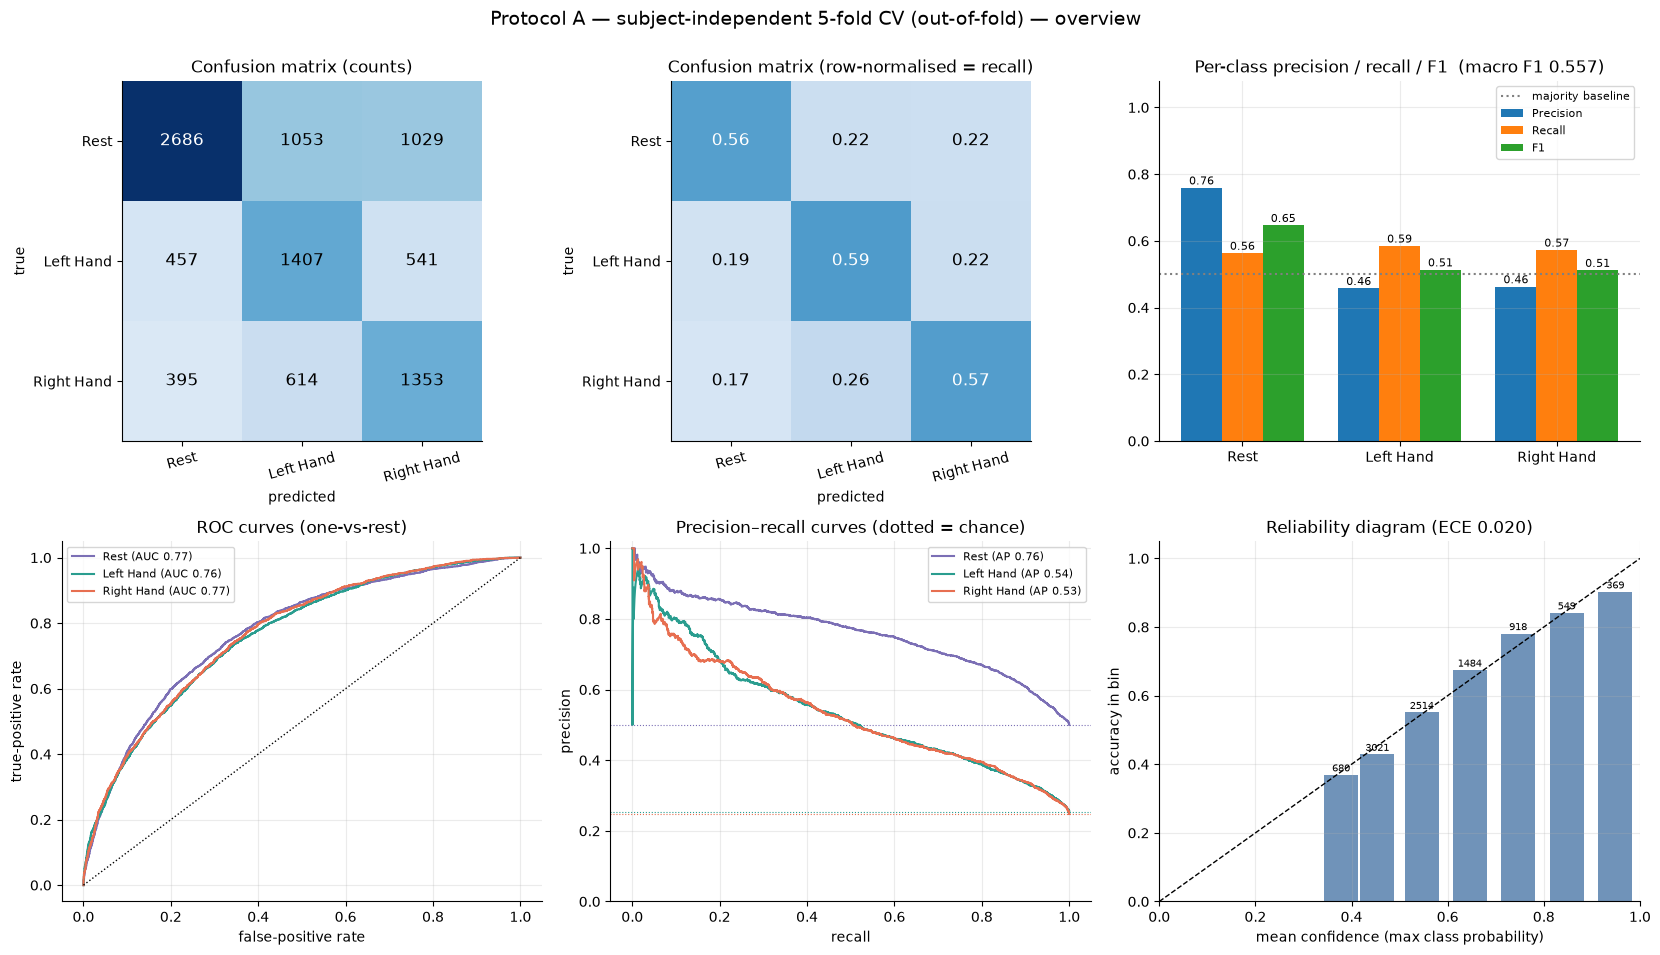

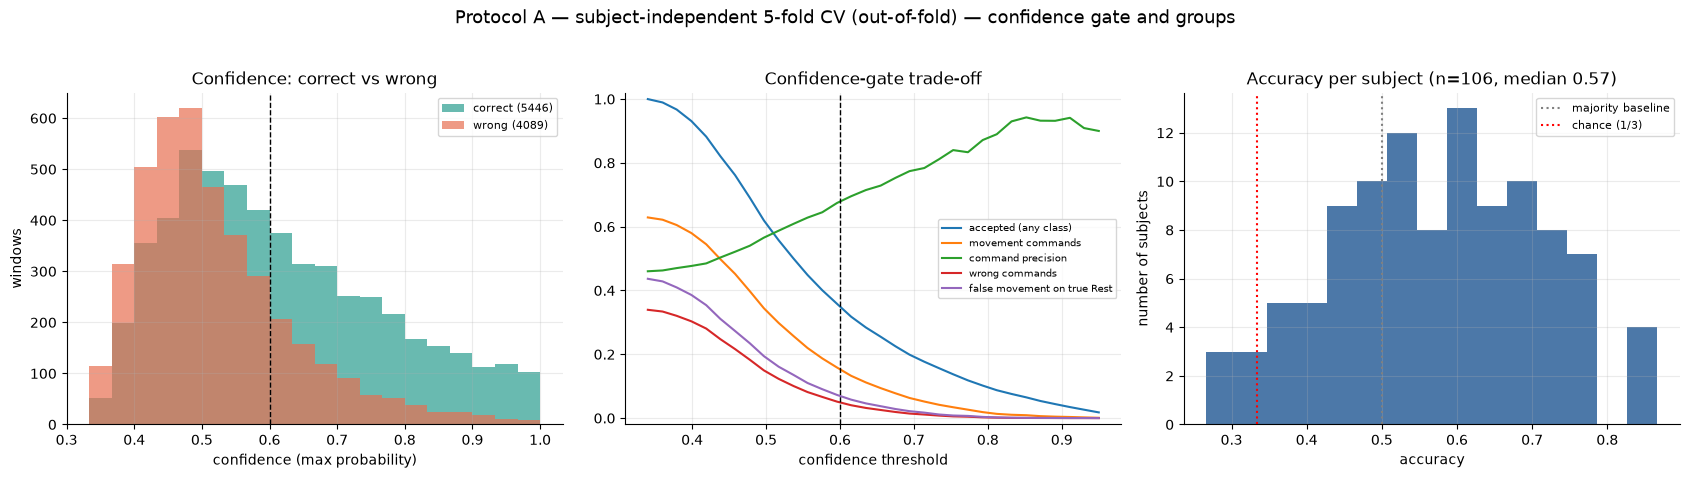

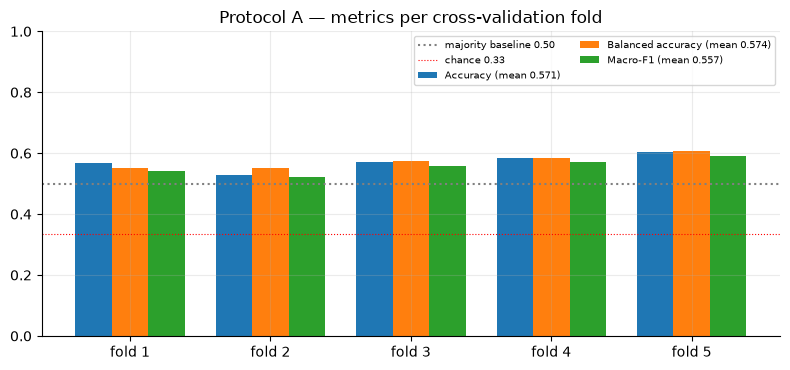

,fold,n_train_subjects,n_val_subjects,n_test_subjects,n_test_epochs,accuracy,balanced_accuracy,macro_f1,best_epoch,temperature,val_selected_threshold
0,1,71,13,22,1975,0.567,0.551,0.543,23,0.769,0.60
1,2,72,13,21,1890,0.529,0.551,0.522,23,1.174,0.80
2,3,72,13,21,1890,0.572,0.576,0.558,59,0.958,0.65
3,4,72,13,21,1890,0.586,0.585,0.571,58,0.726,0.70
4,5,72,13,21,1890,0.603,0.607,0.590,50,0.779,0.65


,subject,n_epochs,fold,accuracy,balanced_accuracy,macro_f1,note
2,S003,90,2,0.267,0.340,0.253,lowest-scoring subjects
96,S099,90,3,0.278,0.364,0.252,lowest-scoring subjects
46,S047,90,2,0.289,0.390,0.257,lowest-scoring subjects
8,S009,90,2,0.333,0.393,0.335,lowest-scoring subjects
36,S037,90,3,0.344,0.364,0.261,lowest-scoring subjects


,subject,n_epochs,fold,accuracy,balanced_accuracy,macro_f1,note
41,S042,90,3,0.778,0.712,0.748,highest-scoring subjects
3,S004,90,5,0.833,0.832,0.812,highest-scoring subjects
6,S007,90,5,0.844,0.865,0.841,highest-scoring subjects
28,S029,90,3,0.856,0.839,0.845,highest-scoring subjects
84,S085,90,4,0.867,0.845,0.863,highest-scoring subjects


In [10]:
cv_metrics, cv_table = show_report(y, res_cv["oof"], subj, "Protocol A — subject-independent 5-fold CV (out-of-fold)", "cv", thr=0.60)
cv_table.to_csv(OUTPUT_ROOT / "all_subject_cross_validation" / "classification_report.csv")
plot_fold_metrics(res_cv["folds"], res_cv["summary"]["majority_baseline_accuracy"], "Protocol A — metrics per cross-validation fold")
display(res_cv["folds"].round(3))
display(res_cv["subjects"].sort_values("accuracy").round(3).head(5).assign(note="lowest-scoring subjects"))
display(res_cv["subjects"].sort_values("accuracy").round(3).tail(5).assign(note="highest-scoring subjects"))

## Step 10 (optional) — Ablations: which ingredient actually helps?

Set `RUN_ABLATIONS = True` in Step 0 to re-run the training recipe with one ingredient removed at a time (plus the optional hemisphere flip).
Each row is a full cross-validation, so this takes ~6× the time of one CV.

In [19]:
if RUN_ABLATIONS:
    def variant(name, **kw):
        r = copy.deepcopy(RECIPE); r["name"] = name
        for k, v in kw.items():
            if k == "aug": r["aug"].update(v)
            else: r[k] = v
        return r
    variants = [variant("no_aug", aug=dict(shift=0, noise=0.0, chdrop=0.0)),
                variant("no_class_weights", balanced=False),
                variant("no_label_smoothing", smoothing=0.0),
                variant("global_norm", norm="global"),
                variant("no_temperature", temperature=False),
                variant("with_hemisphere_flip", aug=dict(flip=True))]
    rows = []
    for v in variants:
        r = run_cv(v, v["name"]); rows.append({"variant": v["name"], **{k: r["summary"][k] for k in ("accuracy", "balanced_accuracy", "macro_f1")}})
    rows.append({"variant": "main recipe (full)", **{k: res_cv["summary"][k] for k in ("accuracy", "balanced_accuracy", "macro_f1")}})
    abl = pd.DataFrame(rows); abl.to_csv(OUTPUT_ROOT / "ablations.csv", index=False); display(abl)
else:
    print("ablations skipped (RUN_ABLATIONS = False)")


=== CV: no_aug (no_aug recipe, norm=per_recording, 5 folds, device=cuda) ===
  fold 1/5: acc=0.597 bal_acc=0.606 F1=0.587 best_epoch=35 T=1.06 (54s)
  fold 2/5: acc=0.557 bal_acc=0.550 F1=0.538 best_epoch=9 T=1.05 (81s)
  fold 3/5: acc=0.570 bal_acc=0.586 F1=0.559 best_epoch=28 T=1.14 (128s)
  fold 4/5: acc=0.542 bal_acc=0.575 F1=0.540 best_epoch=50 T=0.92 (194s)
  fold 5/5: acc=0.621 bal_acc=0.616 F1=0.605 best_epoch=26 T=0.99 (239s)

=== CV: no_class_weights (no_class_weights recipe, norm=per_recording, 5 folds, device=cuda) ===
  fold 1/5: acc=0.573 bal_acc=0.540 F1=0.539 best_epoch=13 T=0.70 (32s)
  fold 2/5: acc=0.559 bal_acc=0.543 F1=0.535 best_epoch=19 T=0.84 (73s)
  fold 3/5: acc=0.607 bal_acc=0.549 F1=0.553 best_epoch=53 T=1.02 (144s)
  fold 4/5: acc=0.599 bal_acc=0.566 F1=0.566 best_epoch=44 T=0.69 (214s)
  fold 5/5: acc=0.610 bal_acc=0.585 F1=0.582 best_epoch=50 T=0.74 (285s)

=== CV: no_label_smoothing (no_label_smoothing recipe, norm=per_recording, 5 folds, device=cuda) =

,variant,accuracy,balanced_accuracy,macro_f1
0,no_aug,0.577556,0.586927,0.567026
1,no_class_weights,0.589617,0.556594,0.555374
2,no_label_smoothing,0.561720,0.553982,0.542376
3,global_norm,0.520713,0.526002,0.508977
4,no_temperature,0.570739,0.574873,0.557754
5,with_hemisphere_flip,0.568222,0.574811,0.556386
6,main recipe (full),0.571159,0.573730,0.557458


## Step 11 — Protocol A: train the deployment model for the app

Cross-validation (Step 8) tells you how well the *recipe* generalizes; now we train **one final model** to hand to the app.

* **Demo subjects** (`N_DEMO_SUBJECTS`, default 6) are removed completely – not for training, validation or calibration. Select exactly these subjects in the app's
  sidebar to show the system on people it has genuinely never seen. Their accuracy below is the honest "held-out demo" score.
* **Validation subjects** (15 % of the rest) choose the best epoch, fit the temperature `T`, and choose the confidence threshold.
* **Training subjects** are everything else.

Afterwards `T` is baked into the final layer and we verify numerically that `softmax(new_logits) == softmax(old_logits / T)`.

demo (held-out) subjects: ['S010', 'S046', 'S068', 'S079', 'S094', 'S108']
train subjects: 85 | validation subjects: 15 | demo subjects: 6
trained in 79s, best epoch = 40
temperature T = 0.844 | validation-selected confidence threshold = 0.70
max |probability difference| after baking T into the weights: 4.76837158203125e-07
{
 "demo_subjects": [
  "S010",
  "S046",
  "S068",
  "S079",
  "S094",
  "S108"
 ],
 "n_epochs": 540,
 "accuracy": 0.6092592592592593,
 "balanced_accuracy": 0.5925925925925926,
 "macro_f1": 0.5860590189938174,
 "gate": {
  "threshold": 0.7,
  "accepted_rate": 0.24444444444444444,
  "accepted_accuracy": 0.7878787878787878,
  "movement_command_rate": 0.07777777777777778,
  "correct_command_rate": 0.05925925925925926,
  "wrong_command_rate": 0.018518518518518517,
  "command_precision": 0.7619047619047619,
  "false_movement_on_true_rest_rate": 0.018518518518518517
 },
 "majority_baseline_accuracy": 0.5
}


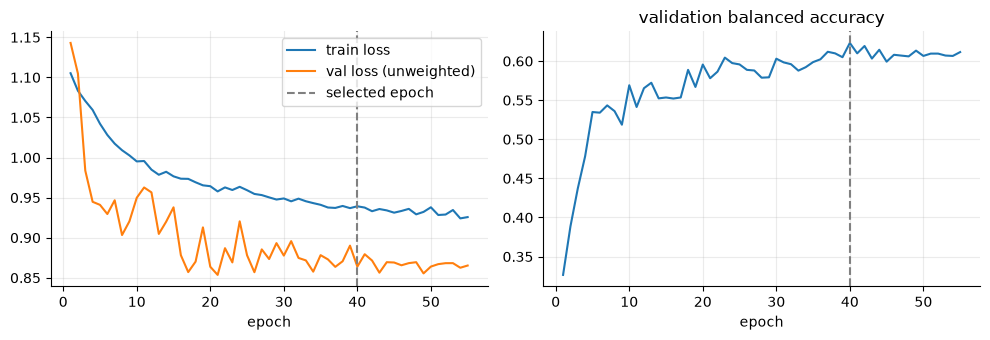

In [11]:
rng = np.random.default_rng(SEED)
demo_subjects = sorted(rng.choice(SUBJECTS, size=min(N_DEMO_SUBJECTS, len(SUBJECTS) // 3), replace=False).tolist())
rest_idx = np.where(~np.isin(subj, demo_subjects))[0]
a, b = next(GroupShuffleSplit(1, test_size=VAL_FRACTION, random_state=SEED).split(rest_idx, groups=subj[rest_idx]))
tr_idx, va_idx = rest_idx[a], rest_idx[b]
demo_idx = np.where(np.isin(subj, demo_subjects))[0]
print("demo (held-out) subjects:", demo_subjects)
print(f"train subjects: {len(np.unique(subj[tr_idx]))} | validation subjects: {len(np.unique(subj[va_idx]))} | demo subjects: {len(demo_subjects)}")

R = copy.deepcopy(RECIPE)
Xn_all, gstats = prepare_inputs(R["norm"], tr_idx)
t0 = time.time()
final_model, info = train_model(Xn_all[tr_idx], y[tr_idx], Xn_all[va_idx], y[va_idx], R, SEED)
print(f"trained in {time.time()-t0:.0f}s, best epoch = {info['best_epoch']}")

lg_va = predict_logits(final_model, Xn_all[va_idx])
T_FINAL = fit_temperature(lg_va, y[va_idx]) if R["temperature"] else 1.0
THRESHOLD_FINAL = float(np.clip(select_threshold(softmax(lg_va / T_FINAL), y[va_idx]), 0.50, 0.95))
print(f"temperature T = {T_FINAL:.3f} | validation-selected confidence threshold = {THRESHOLD_FINAL:.2f}")

before = softmax(predict_logits(final_model, Xn_all[demo_idx]) / T_FINAL)
bake_temperature(final_model, T_FINAL)
after = softmax(predict_logits(final_model, Xn_all[demo_idx]))
print("max |probability difference| after baking T into the weights:", float(np.abs(before - after).max()))
assert np.abs(before - after).max() < 1e-4

pd_pred = after.argmax(1)
demo_report = {"demo_subjects": demo_subjects, "n_epochs": int(len(demo_idx)),
               "accuracy": float(accuracy_score(y[demo_idx], pd_pred)),
               "balanced_accuracy": float(balanced_accuracy_score(y[demo_idx], pd_pred)),
               "macro_f1": float(f1_score(y[demo_idx], pd_pred, average="macro")),
               "gate": gate_stats(after, y[demo_idx], THRESHOLD_FINAL),
               "majority_baseline_accuracy": float(np.bincount(y[demo_idx], minlength=3).max() / len(demo_idx))}
print(json.dumps(demo_report, indent=1))

h = info["history"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h["epoch"], h["train_loss"], label="train loss"); ax[0].plot(h["epoch"], h["val_loss"], label="val loss (unweighted)")
ax[0].axvline(info["best_epoch"], color="gray", ls="--", label="selected epoch"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(h["epoch"], h["val_bal_acc"]); ax[1].axvline(info["best_epoch"], color="gray", ls="--"); ax[1].set_title("validation balanced accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); OUTPUT_ROOT.mkdir(parents=True, exist_ok=True); plt.savefig(OUTPUT_ROOT / "deployment_training_curves.png", dpi=130); plt.show()

## Step 12 — Export the files the app loads

Two files, in the folder and with the names the app's sidebar uses by default:

1. **`neuromotion_all_subject_eegnet_state_dict.pt`** – the PyTorch `state_dict` (CPU tensors). The app builds `EEGNet(n_chans, n_outputs, n_times, sfreq)` from the JSON and calls `load_state_dict(..., strict=True)`.
2. **`neuromotion_all_subject_eegnet_config.json`** – everything the app needs to recreate the preprocessing: channel names **in order**, band-pass, epoch window, label mapping,
   normalization description and the default confidence threshold.

Design decisions that keep the app safe:
* The config has **no `"subject"` key** (a `subject` key would make the app refuse other subjects).
* In `per_recording` mode the config intentionally contains **no** global mean/std.


In [12]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
WEIGHTS_PATH = ARTIFACT_DIR / "neuromotion_all_subject_eegnet_state_dict.pt"
CONFIG_PATH = ARTIFACT_DIR / "neuromotion_all_subject_eegnet_config.json"
for p in (WEIGHTS_PATH, CONFIG_PATH):                       # keep any previous artifact
    if p.exists():
        shutil.copy(p, p.with_name(p.stem + "_backup_" + datetime.now().strftime("%Y%m%d_%H%M%S") + p.suffix))

torch.save({k: v.detach().cpu() for k, v in final_model.state_dict().items()}, WEIGHTS_PATH)

if R["norm"] == "per_recording":
    norm_cfg = {"method": "per_recording_channel_zscore",
                "description": "z-score every channel with the mean/std of the loaded recording (all epochs, all time points), in microvolts"}
else:
    norm_cfg = {"method": "global_channel_zscore", "channel_mean_microvolts": gstats[0].tolist(), "channel_std_microvolts": gstats[1].tolist()}

config = {
    "model": "Braindecode EEGNet (default hyper-parameters)", "model_class": "braindecode.models.EEGNet",
    "training_scope": "All-subject model (subject-independent)", "n_training_subjects": int(len(np.unique(subj[tr_idx]))),
    "n_channels": int(N_CHANNELS), "n_outputs": 3, "n_times": int(N_TIMES), "sampling_rate_hz": SAMPLING_RATE,
    "channel_names_in_order": CH_NAMES,
    "preprocessing": {"bandpass_hz": list(BANDPASS), "epoch_seconds_after_event": list(EPOCH_WINDOW)},
    "annotation_to_label_id": ANNOTATION_TO_LABEL, "class_names": CLASS_NAMES,
    "normalization": norm_cfg,
    "confidence_threshold": THRESHOLD_FINAL, "temperature_baked_into_weights": round(T_FINAL, 4),
    "held_out_demo_subjects": demo_subjects, "training_recipe": {k: v for k, v in R.items()},
    "cv_summary": {k: res_cv["summary"][k] for k in ("accuracy", "balanced_accuracy", "macro_f1", "majority_baseline_accuracy")},
    "held_out_demo_report": demo_report,
    "created": datetime.now().isoformat(timespec="seconds"),
    "disclaimer": "Research prototype for recorded-EEG replay only. Not a medical device."}
CONFIG_PATH.write_text(json.dumps(config, indent=2))
print("saved:", WEIGHTS_PATH.resolve()); print("saved:", CONFIG_PATH.resolve())

saved: C:\Users\cdsch\OneDrive\Documents\AIS\NeuroMotion\artifacts\all_subject_deployment\neuromotion_all_subject_eegnet_state_dict.pt
saved: C:\Users\cdsch\OneDrive\Documents\AIS\NeuroMotion\artifacts\all_subject_deployment\neuromotion_all_subject_eegnet_config.json


## Step 13 — Contract test: does the exported model really work the way `app.py` will use it?

This cell re-implements what the app does — reading the JSON, building `EEGNet` from it, `load_state_dict(strict=True)`, loading an EDF through the
app's `load_recording` logic (copied here, including the per-recording branch of the patch), softmax, confidence gate — **independently of the training code above**.
It then checks that:

1. the weights load with `strict=True`;
2. the app-style probabilities equal the notebook's probabilities on the same demo recording (differences ≈ 1e-6);
3. the config has all keys the app reads and no `subject` key.

If any check fails the notebook stops, so you never ship an artifact the app cannot use.

In [13]:
def app_style_load_model(weights_path, config_path):
    config = json.loads(Path(config_path).read_text())
    model = EEGNet(n_chans=int(config["n_channels"]), n_outputs=int(config.get("n_outputs", 3)),
                   n_times=int(config["n_times"]), sfreq=float(config.get("sampling_rate_hz", 160.0)))
    model.load_state_dict(torch.load(weights_path, map_location="cpu", weights_only=True), strict=True)
    return model.eval(), config

def app_style_load_recording(path, config):               # mirrors app.load_recording (patched normalisation)
    raw = mne.io.read_raw_edf(path, preload=True, verbose="ERROR")
    assert np.isclose(raw.info["sfreq"], float(config.get("sampling_rate_hz", 160.0)))
    raw.pick(picks="eeg"); expected = list(config["channel_names_in_order"])
    assert not (set(expected) - set(raw.ch_names)) and not (set(raw.ch_names) - set(expected)), "channel set mismatch"
    raw.pick(picks=expected)
    bp = config["preprocessing"]["bandpass_hz"]; raw.filter(l_freq=float(bp[0]), h_freq=float(bp[1]), picks="eeg", verbose="ERROR")
    e2l = config.get("annotation_to_label_id", {"T0": 0, "T1": 1, "T2": 2})
    events, found = mne.events_from_annotations(raw, regexp=r"^(T0|T1|T2)$", verbose="ERROR")
    eid = {n: found[n] for n in e2l}; w = config["preprocessing"]["epoch_seconds_after_event"]
    ep = mne.Epochs(raw, events, event_id=eid, tmin=float(w[0]), tmax=float(w[1]), baseline=None, picks="eeg",
                    preload=True, reject_by_annotation=True, verbose="ERROR")
    X_uv = ep.get_data().astype(np.float32) * 1e6
    norm_cfg = config.get("normalization", {})
    if norm_cfg.get("method") == "per_recording_channel_zscore":
        mean = X_uv.mean(axis=(0, 2), keepdims=True).astype(np.float32); std = X_uv.std(axis=(0, 2), keepdims=True).astype(np.float32)
    else:
        mv, sv = norm_cfg.get("channel_mean_microvolts"), norm_cfg.get("channel_std_microvolts")
        if mv is None or sv is None: raise ValueError("Model config is missing its training normalization statistics.")
        mean = np.asarray(mv, dtype=np.float32).reshape(1, -1, 1); std = np.asarray(sv, dtype=np.float32).reshape(1, -1, 1)
    std = np.where(std < 1e-6, 1.0, std)
    labels = np.array([{eid[n]: e2l[n] for n in e2l}[int(c)] for c in ep.events[:, 2]])
    return ((X_uv - mean) / std).astype(np.float32), labels

app_model, app_cfg = app_style_load_model(WEIGHTS_PATH, CONFIG_PATH)
required = ["n_channels", "n_times", "sampling_rate_hz", "channel_names_in_order", "preprocessing", "normalization", "class_names", "annotation_to_label_id"]
assert all(k in app_cfg for k in required) and "subject" not in app_cfg and len(app_cfg["channel_names_in_order"]) == app_cfg["n_channels"]
print("config keys OK; weights load with strict=True")

index = build_edf_index(DATA_ROOT); worst = 0.0
final_model.cpu().eval()
for sid in demo_subjects:
    for run in RUNS[:1]:
        Xa, la = app_style_load_recording(index[f"{sid}{run}.edf"], app_cfg)
        with torch.no_grad(): p_app = torch.softmax(app_model(torch.from_numpy(Xa)).reshape(len(Xa), -1), 1).numpy()
        m = rec == f"{sid}{run}"
        Xn_ref = Xn_all[m]
        with torch.no_grad(): p_nb = torch.softmax(final_model(torch.from_numpy(Xn_ref)).reshape(len(Xn_ref), -1), 1).numpy()
        assert Xa.shape == Xn_ref.shape and (la == y[m]).all(), "epoch set / labels differ between notebook and app pipeline"
        worst = max(worst, float(np.abs(p_app - p_nb).max()))
print(f"max |p_app - p_notebook| over demo recordings: {worst:.2e}")
assert worst < 1e-3, "app-style pipeline disagrees with the notebook pipeline"
final_model.to(DEVICE)
print("CONTRACT TEST PASSED")

config keys OK; weights load with strict=True
max |p_app - p_notebook| over demo recordings: 0.00e+00
CONTRACT TEST PASSED


## Step 14 — Protocol A: report for the held-out demo subjects

The deployment model's test set is the handful of **demo subjects** that were excluded from training, validation and calibration. The same full report as Step 9 is shown here.
Only a few people are involved, so these numbers are **noisy** — the cross-validation report in Step 9 is the one to quote. Use this report to see how the exported model (with its baked-in temperature and
its chosen gate threshold) behaves on exactly the people you will pick in the app.


======== Protocol A — deployment model on held-out demo subjects ['S010', 'S046', 'S068', 'S079', 'S094', 'S108'] ========


,value
n_windows,540.0000
accuracy,0.6093
majority_baseline_accuracy,0.5000
balanced_accuracy,0.5926
macro_precision,0.5829
macro_recall,0.5926
macro_f1,0.5861
weighted_f1,0.6137
cohen_kappa,0.3880
mcc,0.3893


,precision,recall,f1,support
Rest,0.739,0.659,0.697,270.0
Left Hand,0.507,0.556,0.530,135.0
Right Hand,0.503,0.563,0.531,135.0
macro avg,0.583,0.593,0.586,540.0
weighted avg,0.622,0.609,0.614,540.0
accuracy,NaN,NaN,0.609,540.0


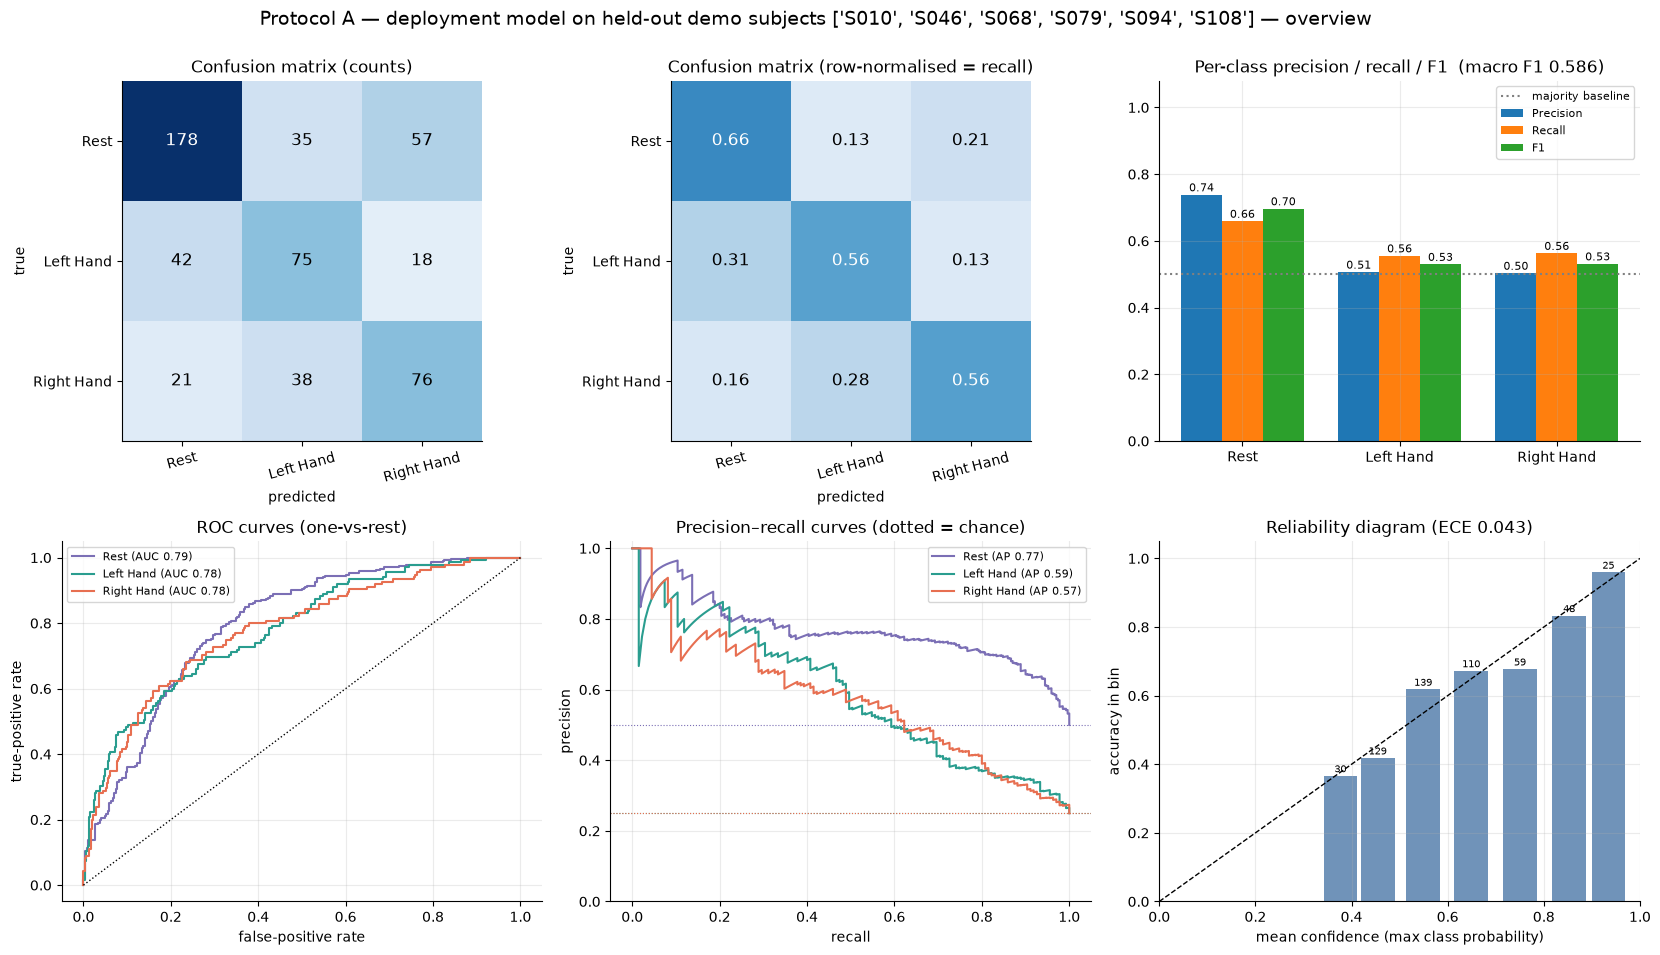

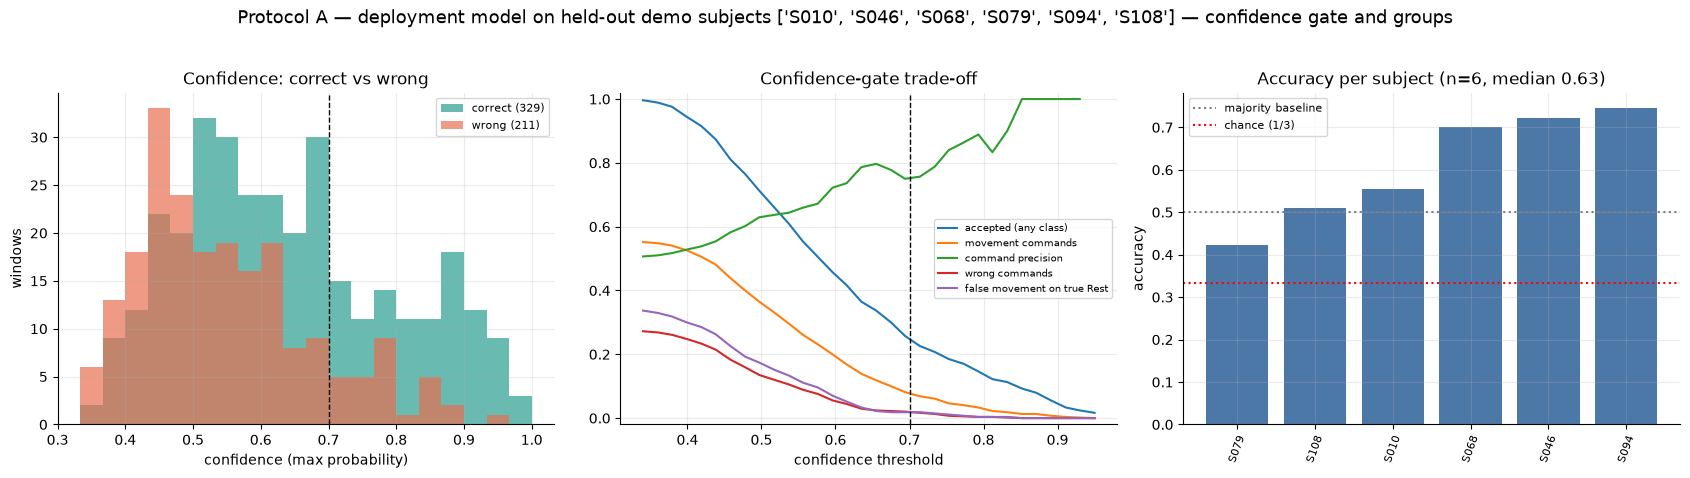

In [14]:
demo_metrics, demo_table = show_report(y[demo_idx], after, subj[demo_idx], f"Protocol A — deployment model on held-out demo subjects {demo_subjects}", "deployment_demo", thr=THRESHOLD_FINAL)

## Step 15 — Protocol B: all-subject model — train on *all* subjects, test on a few held-out *runs* of the best subjects

Steps 7–14 answered "how well does the model work on **new people**?". This step answers a different question:
"how well does a model that has seen **every subject** (but not the specific test runs) work for the people it knows?" — a *within-subject / personalised* protocol.

How the split is built:

1. **Best subjects** = the `N_BEST_SUBJECTS` people with the highest out-of-fold accuracy from the cross-validation in Step 8 (ties broken by balanced accuracy).
2. **Test set** = only the runs listed in `HOLDOUT_RUNS` (default: run `R12`) of those best subjects — e.g. 10 recordings. Set `HOLDOUT_RUNS = ["R08", "R12"]` to hold out two runs per subject
   (each subject then keeps only one run, R04, in training).
3. **Training set** = *everything else*: all runs of all other subjects **and** the remaining runs of the best subjects.
4. **Validation set** = ~15 % of the remaining *recordings* (chosen at random, never from the test runs) for epoch selection, temperature scaling and the gate threshold.

The model, recipe, normalization, calibration and export are identical to Step 11 — only the split differs. The files go to a **separate folder**
(`../artifacts/all_subjects_best_runs_holdout/`) so your Step 11 artifact is not overwritten; to demo this model, paste its two paths into the app sidebar.

> **How to read the result (important).** The score will normally be **higher** than the cross-validation score, for two reasons that have nothing to do with a better algorithm:
> (a) the test runs belong to people whose *other* runs are in training (same electrodes, same brain, same session), and
> (b) the test subjects were picked *because* they decode well. So this number shows what personalisation can reach for good decoders — **never quote it as general accuracy**.
> The cell prints the subject-independent (out-of-fold) result on the *same* test epochs next to it, so you can see exactly how much the extra exposure helps.

best subjects: ['S085', 'S029', 'S007', 'S004', 'S094', 'S020', 'S042', 'S052', 'S035', 'S054']
held-out test recordings: ['S085R12', 'S029R12', 'S007R12', 'S004R12', 'S094R12', 'S020R12', 'S042R12', 'S052R12', 'S035R12', 'S054R12']
train epochs: 7825 (106 subjects) | validation epochs: 1410 (47 recordings) | test epochs: 300
trained in 89s, best epoch = 55
temperature T = 0.765 | validation-selected threshold = 0.70


,accuracy,balanced_accuracy,macro_f1
model,,,
"Protocol B: all subjects in training, best-subject runs held out",0.840,0.842,0.83
Protocol A CV: subject-independent (same test epochs),0.837,0.820,0.82
majority class (always Rest),0.500,0.333,NaN


,recording,n_epochs,accuracy,accuracy_subject_independent
0,S085R12,30,0.967,0.933
1,S029R12,30,0.900,0.833
2,S007R12,30,0.867,0.867
3,S004R12,30,0.933,0.933
4,S094R12,30,0.800,0.767
5,S020R12,30,0.867,0.833
6,S042R12,30,0.800,0.800
7,S052R12,30,0.800,0.767
8,S035R12,30,0.667,0.767
9,S054R12,30,0.800,0.867


gate at threshold 0.7 -> {"threshold": 0.7, "accepted_rate": 0.497, "accepted_accuracy": 0.973, "movement_command_rate": 0.213, "correct_command_rate": 0.207, "wrong_command_rate": 0.007, "command_precision": 0.969, "false_movement_on_true_rest_rate": 0.007}
confusion matrix (rows = true Rest/Left/Right):
 [[125  17   8]
 [  5  67   3]
 [  4  11  60]]

======== Protocol B — all-subject model on held-out runs of the best subjects ========


,value
n_windows,300.0000
accuracy,0.8400
majority_baseline_accuracy,0.5000
balanced_accuracy,0.8422
macro_precision,0.8277
macro_recall,0.8422
macro_f1,0.8301
weighted_f1,0.8427
cohen_kappa,0.7493
mcc,0.7538


,precision,recall,f1,support
Rest,0.933,0.833,0.880,150.0
Left Hand,0.705,0.893,0.788,75.0
Right Hand,0.845,0.800,0.822,75.0
macro avg,0.828,0.842,0.830,300.0
weighted avg,0.854,0.840,0.843,300.0
accuracy,NaN,NaN,0.840,300.0


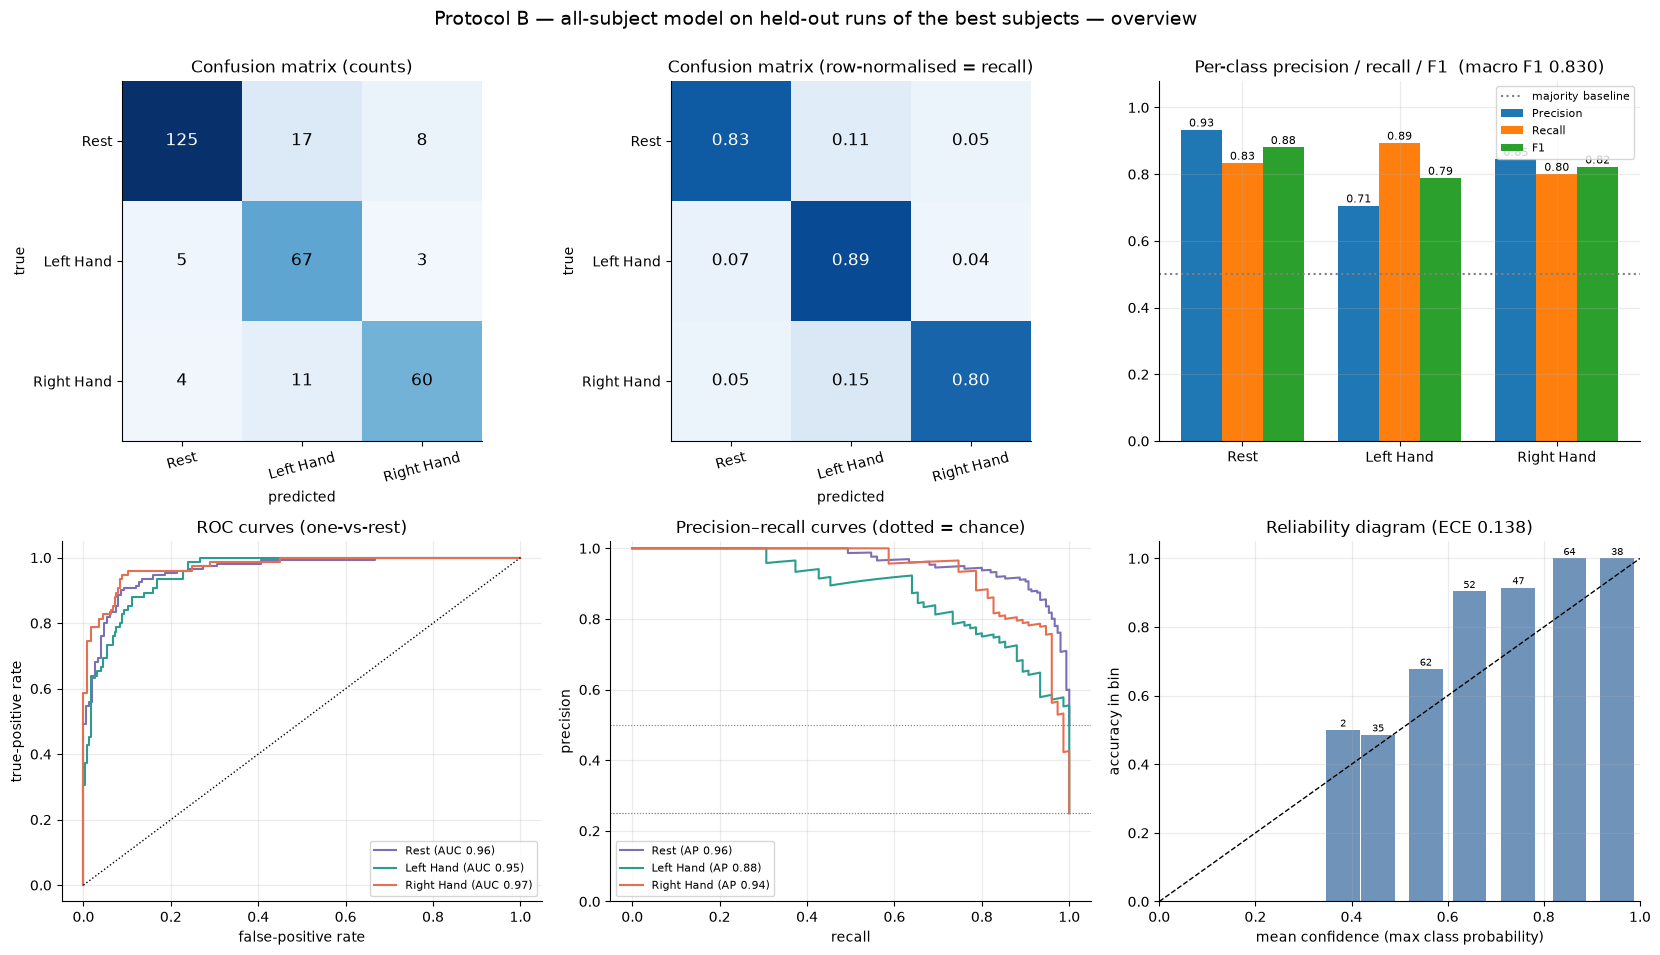

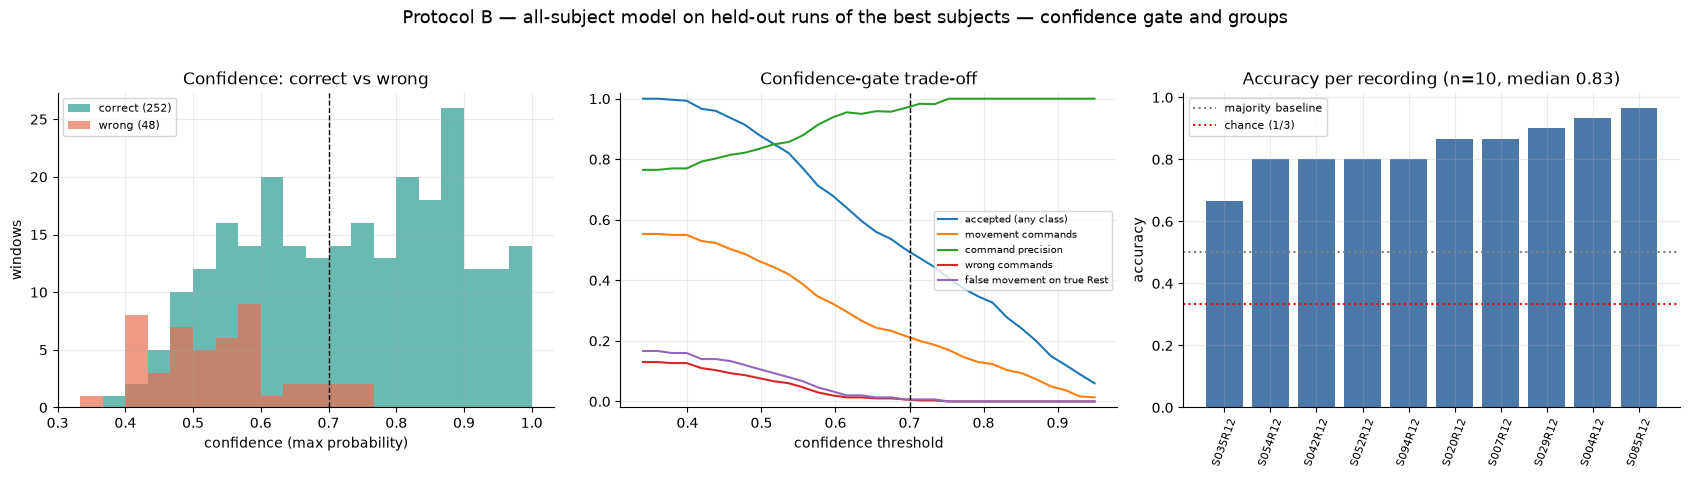


Side-by-side on the identical test epochs:


,Protocol B (all subjects in training),Protocol A CV (subject-independent)
n_windows,300.0000,300.0000
accuracy,0.8400,0.8367
majority_baseline_accuracy,0.5000,0.5000
balanced_accuracy,0.8422,0.8200
macro_precision,0.8277,0.8213
macro_recall,0.8422,0.8200
macro_f1,0.8301,0.8199
weighted_f1,0.8427,0.8374
cohen_kappa,0.7493,0.7390
mcc,0.7538,0.7394


Protocol B                       Protocol A CV                \
              precision recall     f1 support     precision recall     f1   
Rest              0.933  0.833  0.880   150.0         0.893  0.887  0.890   
Left Hand         0.705  0.893  0.788    75.0         0.728  0.787  0.756   
Right Hand        0.845  0.800  0.822    75.0         0.843  0.787  0.814   
macro avg         0.828  0.842  0.830   300.0         0.821  0.820  0.820   
weighted avg      0.854  0.840  0.843   300.0         0.839  0.837  0.837   
accuracy            NaN    NaN  0.840   300.0           NaN    NaN  0.837   

                      
             support  
Rest           150.0  
Left Hand       75.0  
Right Hand      75.0  
macro avg      300.0  
weighted avg   300.0  
accuracy       300.0

In [15]:
N_BEST_SUBJECTS = 3 if QUICK_RUN else 10
HOLDOUT_RUNS = ["R12"]                    # e.g. ["R08", "R12"] for two held-out runs per best subject
ARTIFACT_DIR_B = ARTIFACT_DIR.parent / "all_subjects_best_runs_holdout"

# --- 1. best subjects from the subject-independent CV (Step 8) ---
ranking = res_cv["subjects"].sort_values(["accuracy", "balanced_accuracy"], ascending=False)
best_subjects = ranking["subject"].head(N_BEST_SUBJECTS).tolist()
test_recs = [f"{s}{r}" for s in best_subjects for r in HOLDOUT_RUNS]
assert all(r in set(rec) for r in test_recs), "a requested test recording is not in the loaded data"
test_idx2 = np.where(np.isin(rec, test_recs))[0]
rest2 = np.where(~np.isin(rec, test_recs))[0]

# --- 2. validation recordings (random, never from the test runs) ---
a2, b2 = next(GroupShuffleSplit(1, test_size=VAL_FRACTION, random_state=SEED).split(rest2, groups=rec[rest2]))
tr_idx2, va_idx2 = rest2[a2], rest2[b2]
assert not set(rec[test_idx2]) & (set(rec[tr_idx2]) | set(rec[va_idx2])), "recording leakage"
print("best subjects:", best_subjects)
print("held-out test recordings:", test_recs)
print(f"train epochs: {len(tr_idx2)} ({len(np.unique(subj[tr_idx2]))} subjects) | validation epochs: {len(va_idx2)} "
      f"({len(np.unique(rec[va_idx2]))} recordings) | test epochs: {len(test_idx2)}")

# --- 3. train / calibrate / pick gate threshold (same recipe as Step 11) ---
R2 = copy.deepcopy(RECIPE)
Xn2, gstats2 = prepare_inputs(R2["norm"], tr_idx2)
t0 = time.time()
model2, info2 = train_model(Xn2[tr_idx2], y[tr_idx2], Xn2[va_idx2], y[va_idx2], R2, SEED)
print(f"trained in {time.time()-t0:.0f}s, best epoch = {info2['best_epoch']}")
lg_va2 = predict_logits(model2, Xn2[va_idx2])
T2 = fit_temperature(lg_va2, y[va_idx2]) if R2["temperature"] else 1.0
THR2 = float(np.clip(select_threshold(softmax(lg_va2 / T2), y[va_idx2]), 0.50, 0.95))
bake_temperature(model2, T2)
print(f"temperature T = {T2:.3f} | validation-selected threshold = {THR2:.2f}")

# --- 4. test on the held-out runs ---
p2 = softmax(predict_logits(model2, Xn2[test_idx2])); pred2 = p2.argmax(1); yt = y[test_idx2]
p_si = res_cv["oof"][test_idx2]; pred_si = p_si.argmax(1)          # subject-independent model, same epochs
cmp2 = pd.DataFrame({
    "model": ["Protocol B: all subjects in training, best-subject runs held out", "Protocol A CV: subject-independent (same test epochs)", "majority class (always Rest)"],
    "accuracy": [accuracy_score(yt, pred2), accuracy_score(yt, pred_si), float(np.bincount(yt, minlength=3).max() / len(yt))],
    "balanced_accuracy": [balanced_accuracy_score(yt, pred2), balanced_accuracy_score(yt, pred_si), 1 / 3],
    "macro_f1": [f1_score(yt, pred2, average="macro"), f1_score(yt, pred_si, average="macro"), np.nan]}).set_index("model")
display(cmp2.round(3))
per_rec2 = pd.DataFrame([{"recording": r, "n_epochs": int((rec[test_idx2] == r).sum()),
                          "accuracy": accuracy_score(yt[rec[test_idx2] == r], pred2[rec[test_idx2] == r]),
                          "accuracy_subject_independent": accuracy_score(yt[rec[test_idx2] == r], pred_si[rec[test_idx2] == r])}
                         for r in test_recs])
display(per_rec2.round(3))
gate2 = gate_stats(p2, yt, THR2); print("gate at threshold", THR2, "->", json.dumps({k: round(v, 3) for k, v in gate2.items()}))
cm2 = confusion_matrix(yt, pred2, labels=[0, 1, 2]); print("confusion matrix (rows = true Rest/Left/Right):\n", cm2)

# --- 5. full report (same toolkit as Protocol A) + side-by-side with the subject-independent model on the SAME epochs ---
am_metrics, am_table = show_report(yt, p2, rec[test_idx2], "Protocol B — all-subject model on held-out runs of the best subjects", "all_subject_best_runs", thr=THR2)
si_metrics = metrics_summary(yt, p_si)
print("\nSide-by-side on the identical test epochs:")
display(pd.DataFrame({"Protocol B (all subjects in training)": am_metrics, "Protocol A CV (subject-independent)": si_metrics}).round(4))
display(pd.concat({"Protocol B": am_table, "Protocol A CV": classification_table(yt, p_si)}, axis=1).round(3))

## Step 15b — Export and contract-test the second model

Same two-file export as Step 12, into `../artifacts/all_subjects_best_runs_holdout/`, plus a results JSON. The config lists the **held-out test recordings** so you know exactly which
subject + run to select in the app to see predictions on data this model never trained on (other recordings of those subjects were in training, so they would look better than they should).
The same independent app-style loader as in Step 13 then confirms the files load strictly and reproduce the notebook's predictions.

In [16]:
ARTIFACT_DIR_B.mkdir(parents=True, exist_ok=True)
W2 = ARTIFACT_DIR_B / "neuromotion_all_subjects_best_runs_holdout_eegnet_state_dict.pt"
C2 = ARTIFACT_DIR_B / "neuromotion_all_subjects_best_runs_holdout_eegnet_config.json"
torch.save({k: v.detach().cpu() for k, v in model2.state_dict().items()}, W2)

cfg2 = copy.deepcopy(config)                                   # same preprocessing/channels/labels as Step 12
cfg2["training_scope"] = "All subjects; test = held-out runs of the best subjects (within-subject protocol, NOT subject-independent)"
cfg2["n_training_subjects"] = int(len(np.unique(subj[tr_idx2])))
cfg2["normalization"] = ({"method": "per_recording_channel_zscore",
                          "description": "z-score every channel with the mean/std of the loaded recording (all epochs, all time points), in microvolts"}
                         if R2["norm"] == "per_recording" else
                         {"method": "global_channel_zscore", "channel_mean_microvolts": gstats2[0].tolist(), "channel_std_microvolts": gstats2[1].tolist()})
cfg2["confidence_threshold"] = THR2; cfg2["temperature_baked_into_weights"] = round(T2, 4)
cfg2["training_recipe"] = {k: v for k, v in R2.items()}
cfg2.pop("held_out_demo_subjects", None); cfg2.pop("held_out_demo_report", None)
cfg2["best_subjects"] = best_subjects; cfg2["held_out_test_recordings"] = test_recs
cfg2["held_out_test_report"] = {"n_epochs": int(len(test_idx2)), "accuracy": float(cmp2.iloc[0]["accuracy"]),
                                "balanced_accuracy": float(cmp2.iloc[0]["balanced_accuracy"]), "macro_f1": float(cmp2.iloc[0]["macro_f1"]),
                                "same_epochs_subject_independent_accuracy": float(cmp2.iloc[1]["accuracy"]), "gate": gate2,
                                "caveat": "optimistic: best subjects, other runs of the same subjects were in training"}
cfg2["created"] = datetime.now().isoformat(timespec="seconds")
C2.write_text(json.dumps(cfg2, indent=2))
per_rec2.to_csv(ARTIFACT_DIR_B / "held_out_test_recordings_results.csv", index=False)
print("saved:", W2.resolve()); print("saved:", C2.resolve())

# contract test (same independent app-style loader as Step 13)
app_model2, app_cfg2 = app_style_load_model(W2, C2)
assert "subject" not in app_cfg2 and len(app_cfg2["channel_names_in_order"]) == app_cfg2["n_channels"]
model2.cpu().eval(); worst2 = 0.0
for r in test_recs[:3]:
    Xa, la = app_style_load_recording(index[f"{r}.edf"], app_cfg2)
    m = rec == r
    with torch.no_grad():
        pa = torch.softmax(app_model2(torch.from_numpy(Xa)).reshape(len(Xa), -1), 1).numpy()
        pn = torch.softmax(model2(torch.from_numpy(Xn2[m])).reshape(int(m.sum()), -1), 1).numpy()
    assert Xa.shape == Xn2[m].shape and (la == y[m]).all()
    worst2 = max(worst2, float(np.abs(pa - pn).max()))
model2.to(DEVICE)
print(f"max |p_app - p_notebook|: {worst2:.2e}"); assert worst2 < 1e-3
print("CONTRACT TEST PASSED (Protocol B model)")
print("\nIn the app use weights:", W2, "\n             config :", C2, "\nthen pick one of:", test_recs)

saved: C:\Users\cdsch\OneDrive\Documents\AIS\NeuroMotion\artifacts\all_subjects_best_runs_holdout\neuromotion_all_subjects_best_runs_holdout_eegnet_state_dict.pt
saved: C:\Users\cdsch\OneDrive\Documents\AIS\NeuroMotion\artifacts\all_subjects_best_runs_holdout\neuromotion_all_subjects_best_runs_holdout_eegnet_config.json
max |p_app - p_notebook|: 0.00e+00
CONTRACT TEST PASSED (Protocol B model)

In the app use weights: artifacts\all_subjects_best_runs_holdout\neuromotion_all_subjects_best_runs_holdout_eegnet_state_dict.pt 
             config : artifacts\all_subjects_best_runs_holdout\neuromotion_all_subjects_best_runs_holdout_eegnet_config.json 
then pick one of: ['S085R12', 'S029R12', 'S007R12', 'S004R12', 'S094R12', 'S020R12', 'S042R12', 'S052R12', 'S035R12', 'S054R12']


## Step 16 — Final summary and how to use the models in the app

The cell prints the three result sets side by side (all computed on data the respective model did not train on) and the exact steps for the app. How to talk about them honestly:

* **Quote Protocol A cross-validation (Step 9)** as the expected performance on a *new person*, always with the majority baseline.
* The **demo-subject** report (Step 14) is a handful of people — noisy; use it to pick a good recording for the demo.
* **Protocol B (Step 15)** is a personalised, optimistic upper-bound for good decoders. Never quote it as general accuracy.
* The confidence threshold is an operating point, not a guarantee of correctness. This is a research prototype on recorded data, not a medical/prosthetic controller.

In [17]:
rows = {"A: CV, unseen subjects (out-of-fold)": cv_metrics, "A: deployment model, demo subjects": demo_metrics, "B: all-subject model, held-out best-subject runs": am_metrics}
keys = ["n_windows", "accuracy", "majority_baseline_accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "cohen_kappa", "roc_auc_macro_ovr", "log_loss", "ece"]
summary_df = pd.DataFrame({k: {kk: v[kk] for kk in keys} for k, v in rows.items()}).round(3)
summary_df.to_csv(REPORT_DIR / "summary_all_protocols.csv"); display(summary_df)
print("per-class F1 (CV):", {k: round(v, 3) for k, v in res_cv["summary"]["per_class_f1"].items()})
print("\n=== RUN THE APP ===")
print("1. (once) apply the app.py patch from the README:  python patch_app.py app.py")
print("2. streamlit run app.py")
print("3. Protocol A model  -> weights:", WEIGHTS_PATH, "\n                         config :", CONFIG_PATH, "\n   pick a demo subject:", demo_subjects, "| runs R04 / R08 / R12 | default gate threshold:", THRESHOLD_FINAL)
print("4. Protocol B model  -> weights:", W2, "\n                         config :", C2, "\n   pick one of:", test_recs, "| default gate threshold:", THR2)
print("5. Click 'Load model', then 'Load recording', then Play.")

,"A: CV, unseen subjects (out-of-fold)","A: deployment model, demo subjects","B: all-subject model, held-out best-subject runs"
n_windows,9535.000,540.000,300.000
accuracy,0.571,0.609,0.840
majority_baseline_accuracy,0.500,0.500,0.500
balanced_accuracy,0.574,0.593,0.842
macro_precision,0.560,0.583,0.828
macro_recall,0.574,0.593,0.842
macro_f1,0.557,0.586,0.830
cohen_kappa,0.347,0.388,0.749
roc_auc_macro_ovr,0.767,0.784,0.962
log_loss,0.905,0.846,0.470


per-class F1 (CV): {'Rest': 0.647, 'Left Hand': 0.514, 'Right Hand': 0.512}

=== RUN THE APP ===
1. (once) apply the app.py patch from the README:  python patch_app.py app.py
2. streamlit run app.py
3. Protocol A model  -> weights: artifacts\all_subject_deployment\neuromotion_all_subject_eegnet_state_dict.pt 
                         config : artifacts\all_subject_deployment\neuromotion_all_subject_eegnet_config.json 
   pick a demo subject: ['S010', 'S046', 'S068', 'S079', 'S094', 'S108'] | runs R04 / R08 / R12 | default gate threshold: 0.7
4. Protocol B model  -> weights: artifacts\all_subjects_best_runs_holdout\neuromotion_all_subjects_best_runs_holdout_eegnet_state_dict.pt 
                         config : artifacts\all_subjects_best_runs_holdout\neuromotion_all_subjects_best_runs_holdout_eegnet_config.json 
   pick one of: ['S085R12', 'S029R12', 'S007R12', 'S004R12', 'S094R12', 'S020R12', 'S042R12', 'S052R12', 'S035R12', 'S054R12'] | default gate threshold: 0.7
5. Click 'Load mod